# Repressilator inference: relative mean-squared-error objective

PST/GS-ST comparison for the 50-task stochastic repressilator benchmark using relative mean-squared error (Figure 6).

Task parameters are loaded from `params__truth_init.npy`; attribution is provided in [Data sources](../DATA_SOURCES.md). The default `RUN_MODE = "AUTO"` generates missing results with `LOSS_MODE = "relative"`. Use `RUN_MODE = "PLOT"` to analyze compatible saved results. Plotting also computes the target ODE solution and stochastic display ensembles.

Cache filenames contain the legacy token `target_scaled_log`; the active objective is determined by `LOSS_MODE`.

Run from the `RepressilatorPST/` directory using the `PST (Python 3.11)` kernel. See [Running the notebooks](../docs/RUNNING.md) for execution settings and result reuse.

**Authors:** Jose M. G. Vilar$^{1,2}$ and Leonor Saiz$^{3}$  
$^1$ Biofisika Institute (CSIC, UPV/EHU), University of the Basque Country, P.O. Box 644, 48080 Bilbao, Spain  
$^2$ IKERBASQUE, Basque Foundation for Science, 48011 Bilbao, Spain  
$^3$ Department of Biomedical Engineering, University of California, 451 East Health Sciences Drive, Davis, CA 95616, USA

**Preprint:** J. M. G. Vilar and L. Saiz, *Propensity Straight-Through Gradients for Discrete Stochastic Systems*, arXiv:2608.25631 [q-bio.QM] (2026).  
**DOI:** [https://doi.org/10.48550/arXiv.2608.25631](https://doi.org/10.48550/arXiv.2608.25631)


TensorFlow imported quietly; GPUs: 1
TensorFlow floating-point protocol: float32
Exact-path explicit XLA: enabled
Training XLA autoclustering: enabled
Exact reference batch size: 50000
Validation batch size: 50000
Burger task array: (2, 50, 3) | columns: kp=0, Kd=1, h=2 | h truth/init fixed at 3.0
Lowest initial Kd tasks:
   1. task 45 | truth=(34.342, 0.613563) | init=(231.705, 0.275829, h=3)
   2. task 43 | truth=(10.5564, 0.643464) | init=(11.1843, 0.392181, h=3)
   3. task 30 | truth=(288.982, 5.09593) | init=(184.952, 0.62757, h=3)
   4. task 36 | truth=(32.0406, 1.07273) | init=(18.8955, 0.755098, h=3)
   5. task 39 | truth=(80.2001, 1.59298) | init=(77.1074, 0.76088, h=3)
   6. task 29 | truth=(158.516, 4.62391) | init=(68.2317, 0.769521, h=3)
   7. task 40 | truth=(57.8111, 2.00067) | init=(196.483, 1.15573, h=3)
   8. task 48 | truth=(24.8394, 2.39925) | init=(8.99127, 1.18322, h=3)
   9. task 37 | truth=(257.045, 4.44793) | init=(395.2, 1.2575, h=3)
  10. task 32 | truth=(72.


BURGER TASK 1 (1/50 selected) | ref=(497.045,70.2709) | init=(1264.96,31.4874) | period=4.32
  Generating Burger reference mean from 50000 exact trajectories...



  PST: reference (497.045, 70.2709); initial (1264.96, 31.4874)
  PST initial | loss 2.39709e-01 | ||g_log|| 6.08732e-01 | RMSprop lr 1.00000e-01 | clip norm 1.00000e-01 | loss mode relative | mean events 3991.1
  PST final selected | kp 496.708 | Kd 70.3052 | selection loss 2.26702e-07 | selected from refinement | stage1 status snr_stop | refinement completed

  GSST: reference (497.045, 70.2709); initial (1264.96, 31.4874)
  GSST initial | loss 2.45187e-01 | ||g_log|| 5.99271e-01 | RMSprop lr 1.00000e-01 | clip norm 1.00000e-01 | loss mode relative | mean events 3999.4
  GSST final selected | kp 496.905 | Kd 70.2721 | selection loss 2.17259e-07 | selected from refinement | stage1 status snr_stop | refinement completed

BURGER TASK 2 (2/50 selected) | ref=(171.323,17.299) | init=(136.492,16.4464) | period=4.94
  Generating Burger reference mean from 50000 exact trajectories...

  PST: reference (171.323, 17.299); initial (136.492, 16.4464)
  PST initial | loss 1.88615e-02 | ||g_log||

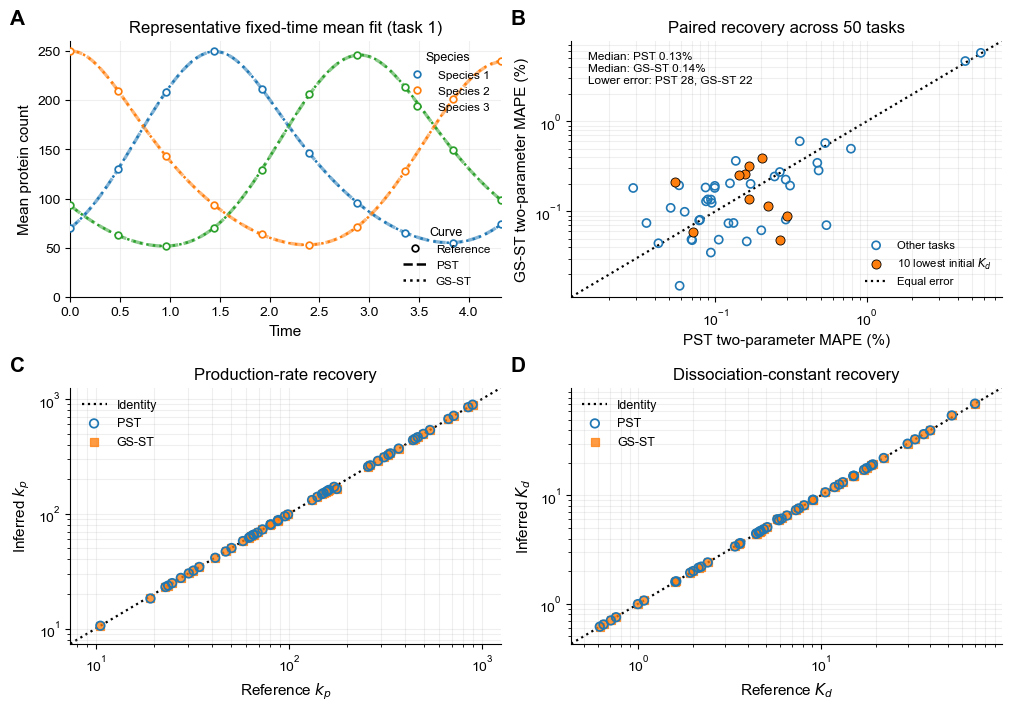

In [ ]:
#!/usr/bin/env python
# coding: utf-8

"""
Stochastic repressilator inference with PST and GS-ST in TensorFlow.

The model and 50 reference/initialization pairs follow the released Burger
et al. benchmark. Simulation uses exact physical-time SSA trajectories,
float32 arithmetic, 50,000 trajectories per target, training evaluation and
validation, and no artificial training event cap. Two log-parameter forward
sensitivities and the temporal straight-through readout are propagated through
the event loop; ensemble observation sums are accumulated inside the loop.

Optimization
------------
Parameters are optimized in log space with TensorFlow/Keras RMSprop:
initial learning rate 0.1, rho 0.9, zero momentum, global gradient-norm
clipping at 0.1, learning-rate decay factor 0.9 every 200 steps, and a
learning-rate floor of 0.001. The RMSprop and learning-rate settings follow
the released Vilar--Saiz oscillator optimizer pattern. Truth-dependent parameter
clipping is not used.

Stage 1 uses the released loss-SNR stopping and rolling-window selection.
Stage 2 starts from the selected pair with a fresh RMSprop optimizer,
learning rate 0.01, and 50 evaluations. Both stages share the model, loss,
estimator, trajectory count and gradient clipping.

Objectives
----------
LOSS_MODE selects one of:
- "relative": mean(((prediction - target) / target)^2)
- "log": mean((log(prediction) - log(target))^2)
- "target_scaled_log": mean(2 * [r log(r) - r + 1]), r = prediction / target

This notebook uses "relative", the relative mean-squared-error objective.
Loss mode is included in the optimization fingerprint. Compatible exact
target caches remain reusable when the objective is changed.

Task selection and caching
--------------------------
Full mode evaluates all 50 released tasks. Optional pilot mode selects either
an explicit task subset or the lowest initial Kd values. Cache namespaces
and implementation-version identifiers retain the provenance of the archived
calculations and distinguish compatible result files.
"""

from __future__ import annotations

import contextlib
import ctypes
import gc
import hashlib
import json
import os

# Respect CUDA_VISIBLE_DEVICES supplied by the caller before importing TensorFlow.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")

import pickle
import time
import urllib.request
from pathlib import Path
from typing import Any

# =============================================================================
# USER CONFIGURATION
# =============================================================================

# Implementation identifiers and cache names are retained for reproducibility.
# The namespace distinguishes forward-sensitivity results from other implementations.

RUN_NAMESPACE = "forward_sensitivity_refinement_v2d"

CODE_VERSION = (
    "burger_tf_reference_protocol_v8_forward_sensitivity_refinement_"
    "rmsprop_target_scaled_log_2026_08_04"
)
# Exact target and validation implementation identifier.
# Target caches use the RUN_NAMESPACE directory
# to distinguish compatible archived runs.
TARGET_CACHE_VERSION = "burger_exact_target_v1_2026_07_28"
TRAINING_IMPLEMENTATION_VERSION = (
    "explicit_forward_sensitivity_two_parameter_v1_reduced_observation_sum_v1_refinement_v1"
)
TARGET_IMPLEMENTATION_VERSION = (
    "per_trajectory_observation_accumulator_reference_v1"
)

RUN_MODE = "AUTO"  # AUTO, TRAIN, PLOT

# Pilot options.
# When True, run only a subset of Burger's 50 tasks.
PILOT_MODE = False

# Recommended stress-test pilot: automatically run the tasks with the smallest
# INITIAL Kd values, i.e. the strong-binding initializations highlighted by
# Burger et al. Set this False to use PILOT_TASK_INDICES literally.
PILOT_SELECT_LOWEST_INITIAL_KD = False
PILOT_N_LOWEST_INITIAL_KD = 10

# Used only when PILOT_SELECT_LOWEST_INITIAL_KD = False.
# Zero-based indices for Burger tasks 14, 30, 34, 42, and 45.
PILOT_TASK_INDICES = (13, 29, 33, 41, 44)

RESULTS_FILE = (
    "burger_repressilator_tf_reference_protocol_float32_gpu_rmsprop_"
    f"target_scaled_log_{RUN_NAMESPACE}.pkl"
)
CHECKPOINT_DIR = (
    "burger_repressilator_tf_reference_float32_gpu_rmsprop_target_scaled_log_"
    f"{RUN_NAMESPACE}_checkpoints"
)
TARGET_CHECKPOINT_DIR = (
    "burger_repressilator_tf_reference_exact_targets_"
    f"{RUN_NAMESPACE}"
)
# Figure 6 output and display configuration. These options affect plotting
# only and are intentionally excluded from the simulation/optimization
# fingerprints, so existing validated result files remain reusable.
FIGURE_PREFIX = "Figure6_Burger_Repressilator_PST_vs_GSST"
FIGURE_REPRESENTATIVE_TASK_INDEX = 0  # zero-based Burger task index
FIGURE_HIGHLIGHT_LOWEST_INITIAL_KD = True
FIGURE_N_HIGHLIGHT_LOWEST_INITIAL_KD = 10
FIGURE_N_CURVE_POINTS = 100
# Panel A keeps the original 10 reference observations as markers, but
# re-evaluates the fitted PST and GS-ST models on this denser exact-SSA
# grid for display only. This does not change inference or its objective.

BURGER_TASK_FILE = "params__truth_init.npy"
BURGER_TASK_URL = (
    "https://raw.githubusercontent.com/"
    "gerland-group/DifferentiableGillespie/main/"
    "figure_scripts/main/repressilator/params__truth_init.npy"
)
AUTO_DOWNLOAD_TASK_FILE = True

BASE_SEED = 2604021

# Released Burger optimization settings.
N_REFERENCE_TRAJECTORIES = 50_000
N_TRAIN_TRAJECTORIES = 50_000 // 1
N_VALIDATION_TRAJECTORIES = 50_000
# Exact target/validation paths do not retain an autodiff tape, so use
# much larger batches to give the GPU enough parallel work. Lower these
# if the exact path exceeds available VRAM.
REFERENCE_BATCH_SIZE = 50_000 // 1
VALIDATION_BATCH_SIZE = 50_000 // 1

# Explicit XLA is safe and useful for exact target/validation because that
# path does not backpropagate through the data-dependent while-loop.
USE_XLA_EXACT = True

# The differentiated training path propagates explicit
# two-parameter forward sensitivities through the physical-time while-loop.
# Keep the whole training function at jit_compile=False for conservative
# compatibility, while retaining the same best-effort XLA autoclustering used
# by the reference implementation.  No artificial event cap is introduced.
USE_XLA_AUTOCLUSTER = True

N_OBSERVATION_TIMES = 10
GSST_TAU_MOL = 0.30
TEMPORAL_TAU = 0.05

# Objective used for parameter inference.
#
# "target_scaled_log":
#     mean(2 * (r * log(r) - r + 1)),  r = prediction / target
#
#     dL/d(prediction) per element =
#         2 * log(prediction / target) / target
#
# "relative":
#     mean(((prediction - target) / target)**2)
#
# "log":
#     mean((log(prediction) - log(target))**2)
#

LOSS_MODE = "relative"

if LOSS_MODE not in {"target_scaled_log", "relative", "log"}:
    raise ValueError(
        "LOSS_MODE must be 'target_scaled_log', 'relative', or 'log'."
    )

# Vilar--Saiz-style standard optimizer in log-parameter space.
RMSPROP_LEARNING_RATE = 0.10
RMSPROP_RHO = 0.90
RMSPROP_MOMENTUM = 0.0
RMSPROP_EPSILON = 1.0e-7
RMSPROP_CENTERED = False

# Global gradient-norm clipping for the repressilator comparison.
GRADIENT_CLIP_NORM = 0.1

# Their oscillator reduces the learning rate every 25*kk epochs; with the
# released default kk=8 this is every 200 steps. Keep it as an explicit toggle
# so the effect of RMSprop can also be tested without annealing.
RMSPROP_LR_DECAY_ENABLED = True
RMSPROP_LR_DECAY_INTERVAL = 200
RMSPROP_LR_DECAY_FACTOR = 0.90
RMSPROP_LR_FLOOR = 1.0e-3

MAX_OPTIMIZATION_STEPS = 1_000
SNR_WINDOW = 50
SNR_THRESHOLD = 0.01

# Second-stage refinement. The selected Stage-1
# log-parameter pair is used to initialize a FRESH RMSprop optimizer at a
# lower learning rate. Refinement uses the same stochastic gradient estimator,
# training-trajectory count, and gradient clipping as Stage 1. It runs for a
# fixed number of evaluations (no SNR stopping and no LR decay), and the best
# measured refinement candidate includes the Stage-1 starting pair itself.
REFINEMENT_ENABLED = True
REFINEMENT_LEARNING_RATE_FACTOR = 0.10
REFINEMENT_MAX_EVALUATIONS = 50

if REFINEMENT_LEARNING_RATE_FACTOR <= 0.0:
    raise ValueError("REFINEMENT_LEARNING_RATE_FACTOR must be positive.")
if REFINEMENT_MAX_EVALUATIONS < 1:
    raise ValueError("REFINEMENT_MAX_EVALUATIONS must be at least 1.")

# The released code continues while violation_count <= 3, so it stops once
# the count becomes 4.
RELEASED_SNR_MAX_ALLOWED = 3

HILL_COEFFICIENT = 3.0
DEGRADATION_RATE = 1.0
VOLUME = 1.0

# Mean-field integration. The released driver integrates from [1,0,0] to t=100.
MEANFIELD_T_MAX = 100.0
MEANFIELD_DT = 0.01

# Numerical constants.
# Burger's released code replaces exactly zero ensemble means by 1e-20.
ZERO_MEAN_REPLACEMENT = 1e-20
GRAD_NORM_EPSILON = 1e-15

SCRIPT_DIR = (
    Path(__file__).resolve().parent
    if "__file__" in globals()
    else Path.cwd()
)
RESULTS_PATH = SCRIPT_DIR / RESULTS_FILE
LEGACY_CONSOLIDATED_FINGERPRINT = "ff044c3dc53792ce678cc52f4bb9bb9145d03c880e890855dcac8966c2dcf2f7"
CHECKPOINT_PATH = SCRIPT_DIR / CHECKPOINT_DIR
TARGET_CHECKPOINT_PATH = SCRIPT_DIR / TARGET_CHECKPOINT_DIR
TASK_PATH = SCRIPT_DIR / BURGER_TASK_FILE

# =============================================================================
# TENSORFLOW SETUP
# =============================================================================

libc = ctypes.CDLL(None)


@contextlib.contextmanager
def silence_native_output():
    saved_out = os.dup(1)
    saved_err = os.dup(2)
    try:
        devnull = os.open(os.devnull, os.O_WRONLY)
        libc.fflush(None)
        os.dup2(devnull, 1)
        os.dup2(devnull, 2)
        os.close(devnull)
        yield
    finally:
        libc.fflush(None)
        os.dup2(saved_out, 1)
        os.dup2(saved_err, 2)
        os.close(saved_out)
        os.close(saved_err)


os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

with silence_native_output():
    import tensorflow as tf

    for gpu in tf.config.list_physical_devices("GPU"):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass

tf.get_logger().setLevel("ERROR")
tf.keras.backend.set_floatx("float32")

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

DTYPE = tf.float32
NP_DTYPE = np.float64
MODEL_NP_DTYPE = np.float32

print(
    "TensorFlow imported quietly; GPUs:",
    len(tf.config.list_physical_devices("GPU")),
)
if USE_XLA_AUTOCLUSTER:
    tf.config.optimizer.set_jit("autoclustering")

print("TensorFlow floating-point protocol: float32")
print("Exact-path explicit XLA:", "enabled" if USE_XLA_EXACT else "disabled")
print(
    "Training XLA autoclustering:",
    "enabled" if USE_XLA_AUTOCLUSTER else "disabled",
)
print("Exact reference batch size:", REFERENCE_BATCH_SIZE)
print("Validation batch size:", VALIDATION_BATCH_SIZE)

# =============================================================================
# MODEL
# =============================================================================

NUM_SPECIES = 3
NUM_REACTIONS = 6

# Columns in Burger's JAX code correspond to:
# +P1, -P1, +P2, -P2, +P3, -P3.
STOICHIOMETRY = tf.constant(
    [
        [1.0, 0.0, 0.0],
        [-1.0, 0.0, 0.0],
        [0.0, 1.0, 0.0],
        [0.0, -1.0, 0.0],
        [0.0, 0.0, 1.0],
        [0.0, 0.0, -1.0],
    ],
    dtype=DTYPE,
)


def repressilator_propensities(
    states: tf.Tensor,
    log_parameters: tf.Tensor,
) -> tf.Tensor:
    """Six Burger repressilator reaction rates for a batch of states."""
    kp = tf.exp(log_parameters[0])
    Kd = tf.exp(log_parameters[1])

    p1 = states[:, 0]
    p2 = states[:, 1]
    p3 = states[:, 2]

    hill = tf.cast(HILL_COEFFICIENT, DTYPE)
    scale = Kd * tf.cast(VOLUME, DTYPE)

    prod1 = kp * VOLUME / (1.0 + tf.pow(p3 / scale, hill))
    prod2 = kp * VOLUME / (1.0 + tf.pow(p1 / scale, hill))
    prod3 = kp * VOLUME / (1.0 + tf.pow(p2 / scale, hill))

    deg1 = DEGRADATION_RATE * p1
    deg2 = DEGRADATION_RATE * p2
    deg3 = DEGRADATION_RATE * p3

    return tf.stack(
        [prod1, deg1, prod2, deg2, prod3, deg3],
        axis=1,
    )


def safe_log_rates(rates: tf.Tensor) -> tf.Tensor:
    """Log propensities with exactly-zero channels represented by -inf."""
    positive = rates > 0.0
    return tf.where(
        positive,
        tf.math.log(tf.where(positive, rates, tf.ones_like(rates))),
        tf.constant(float("-inf"), dtype=DTYPE),
    )


def direct_stoichiometric_increment(weights: tf.Tensor) -> tf.Tensor:
    """
    Convert six reaction weights to the three species increments directly.

    This is algebraically identical to weights @ STOICHIOMETRY, but avoids a
    tiny 6x3 matrix multiplication at every Gillespie event and is easier for
    XLA to fuse with neighboring elementwise operations.
    """
    return tf.stack(
        [
            weights[:, 0] - weights[:, 1],
            weights[:, 2] - weights[:, 3],
            weights[:, 4] - weights[:, 5],
        ],
        axis=1,
    )


def exact_inverse_cdf_increment(
    rates: tf.Tensor,
    total: tf.Tensor,
    reaction_uniform: tf.Tensor,
) -> tf.Tensor:
    """
    Exact categorical SSA reaction draw using a six-channel inverse CDF.

    This is distributionally identical to sampling categorical(log(rates)),
    but avoids log -> categorical -> one_hot -> matmul for the exact/PST path.
    """
    threshold = reaction_uniform * total
    cumulative = tf.cumsum(rates, axis=1)
    reaction_index = tf.reduce_sum(
        tf.cast(
            cumulative < threshold[:, None],
            tf.int32,
        ),
        axis=1,
    )
    reaction_index = tf.minimum(
        reaction_index,
        tf.constant(NUM_REACTIONS - 1, tf.int32),
    )
    return tf.stop_gradient(
        tf.gather(STOICHIOMETRY, reaction_index)
    )


def pst_increment(
    rates: tf.Tensor,
    total: tf.Tensor,
    reaction_uniform: tf.Tensor,
) -> tf.Tensor:
    """
    PST reaction increment.

    Forward: exact inverse-CDF categorical event.
    Backward: normalized-propensity reaction mixture.
    """
    hard_dN = exact_inverse_cdf_increment(
        rates,
        total,
        reaction_uniform,
    )
    probabilities = rates / total[:, None]
    soft_dN = direct_stoichiometric_increment(probabilities)
    return soft_dN + tf.stop_gradient(hard_dN - soft_dN)

def pst_incrementX(
    rates: tf.Tensor,
    total: tf.Tensor,
    reaction_uniform: tf.Tensor,
) -> tf.Tensor:
    """
    PST reaction increment.

    Forward: exact inverse-CDF categorical event.
    Backward: normalized-propensity reaction mixture (denominator blocked).
    """
    hard_dN = exact_inverse_cdf_increment(
        rates,
        total,
        reaction_uniform,
    )
    
    # Block gradients from flowing into the denominator (total)
    stopped_total = tf.stop_gradient(total)
    probabilities = rates / stopped_total[:, None]
    
    soft_dN = direct_stoichiometric_increment(probabilities)
    return soft_dN + tf.stop_gradient(hard_dN - soft_dN)
    
def gsst_increment(
    rates: tf.Tensor,
    gumbel_uniforms: tf.Tensor,
) -> tf.Tensor:
    """
    Vilar--Saiz / Burger reaction GS-ST increment.

    Forward: hard Gumbel-Max reaction.
    Backward: Gumbel-softmax relaxed stoichiometric increment.
    """
    logits = safe_log_rates(rates)
    gumbel = -tf.math.log(-tf.math.log(gumbel_uniforms))
    noisy = logits + gumbel

    hard_index = tf.argmax(
        noisy,
        axis=1,
        output_type=tf.int32,
    )
    hard_dN = tf.stop_gradient(
        tf.gather(STOICHIOMETRY, hard_index)
    )

    relaxed = tf.nn.softmax(
        noisy / tf.cast(GSST_TAU_MOL, DTYPE),
        axis=1,
    )
    soft_dN = direct_stoichiometric_increment(relaxed)
    return soft_dN + tf.stop_gradient(hard_dN - soft_dN)


def simulate_to_observation_times_impl(
    initial_states: tf.Tensor,
    observation_times: tf.Tensor,
    log_parameters: tf.Tensor,
    estimator_id: int,
    seed: tf.Tensor,
    n_observation_times: int = N_OBSERVATION_TIMES,
) -> tuple[tf.Tensor, tf.Tensor]:
    """
    Event-serial, trajectory-vectorized Gillespie simulation to t_max.

    The implementation deliberately keeps the Burger physical-time stopping
    rule, but minimizes per-event GPU launches:
      * one stateless RNG call per event,
      * inverse-CDF categorical sampling for exact/PST,
      * direct stoichiometric increments instead of tiny matrix multiplies,
      * no GPU<->CPU swap-memory traffic.

    estimator_id
    ------------
    0: exact target/validation, no gradient estimator
    1: PST reaction estimator + Burger temporal ST
    2: Vilar--Saiz GS-ST reaction estimator + Burger temporal ST
    """
    states = tf.cast(initial_states, DTYPE)

    # These dimensions are static inside the XLA-specialized callers.
    batch_size = states.shape[0]
    if batch_size is None:
        batch_size = tf.shape(states)[0]

    t = tf.zeros([batch_size], dtype=DTYPE)
    t_max = observation_times[-1]
    # Keep the observation-axis size static for XLA, but do not hard-code it
    # to the 10 inference times.  The dense figure-only validation path below
    # supplies FIGURE_N_CURVE_POINTS (=100) explicitly.
    accumulated = tf.zeros(
        [batch_size, n_observation_times, NUM_SPECIES],
        dtype=DTYPE,
    )
    event_counts = tf.zeros([batch_size], dtype=tf.int32)
    event_step = tf.constant(0, dtype=tf.int32)

    def condition(
        states,
        t,
        accumulated,
        event_counts,
        event_step,
    ):
        del states, accumulated, event_counts, event_step
        return tf.reduce_any(t < t_max)

    def body(
        states,
        t,
        accumulated,
        event_counts,
        event_step,
    ):
        active = t < t_max

        rates = repressilator_propensities(
            states,
            log_parameters,
        )
        total = tf.reduce_sum(rates, axis=1)

        # Active repressilator trajectories have a strictly positive total
        # propensity because production remains possible. Inactive rows are
        # assigned total=1 only to keep masked arithmetic finite.
        safe_total = tf.where(
            active,
            total,
            tf.ones_like(total),
        )

        # Derive one deterministic event seed from the evaluation seed and
        # event index, then generate every uniform needed by the event in one
        # RNG call. This removes two seed-split operations and multiple RNG
        # launches from the hottest loop.
        event_seed = tf.random.experimental.stateless_fold_in(
            seed,
            event_step,
        )

        if estimator_id == 2:
            uniforms = tf.random.stateless_uniform(
                [batch_size, 1 + NUM_REACTIONS],
                seed=event_seed,
                minval=tf.cast(1e-20, DTYPE),
                maxval=tf.cast(1.0, DTYPE),
                dtype=DTYPE,
            )
            u_time = uniforms[:, 0]
            gumbel_uniforms = uniforms[:, 1:]
        else:
            uniforms = tf.random.stateless_uniform(
                [batch_size, 2],
                seed=event_seed,
                minval=tf.cast(1e-20, DTYPE),
                maxval=tf.cast(1.0, DTYPE),
                dtype=DTYPE,
            )
            u_time = uniforms[:, 0]
            reaction_uniform = uniforms[:, 1]

        dt = -tf.math.log(u_time) / safe_total
        dt = tf.where(active, dt, tf.zeros_like(dt))

        if estimator_id == 0:
            dN = exact_inverse_cdf_increment(
                rates,
                safe_total,
                reaction_uniform,
            )
        elif estimator_id == 1:
            dN = pst_increment(
                rates,
                safe_total,
                reaction_uniform,
            )
        elif estimator_id == 2:
            dN = gsst_increment(
                rates,
                gumbel_uniforms,
            )
        else:
            raise ValueError("estimator_id must be 0, 1, or 2")

        dN = tf.where(
            active[:, None],
            dN,
            tf.zeros_like(dN),
        )

        t_new = t + dt
        states_new = states + dN

        hard_time = tf.cast(
            t_new[:, None] <= observation_times[None, :],
            DTYPE,
        )

        if estimator_id == 0:
            effective_time = tf.stop_gradient(hard_time)
        else:
            soft_time = tf.math.sigmoid(
                (
                    observation_times[None, :]
                    - t_new[:, None]
                )
                / tf.cast(TEMPORAL_TAU, DTYPE)
            )
            effective_time = (
                soft_time
                + tf.stop_gradient(hard_time - soft_time)
            )

        effective_time = tf.where(
            active[:, None],
            effective_time,
            tf.zeros_like(effective_time),
        )

        accumulated_new = (
            accumulated
            + effective_time[:, :, None] * dN[:, None, :]
        )
        event_counts_new = (
            event_counts
            + tf.cast(active, tf.int32)
        )

        return (
            states_new,
            t_new,
            accumulated_new,
            event_counts_new,
            event_step + 1,
        )

    (
        _,
        _,
        accumulated,
        event_counts,
        _,
    ) = tf.while_loop(
        condition,
        body,
        loop_vars=(
            states,
            t,
            accumulated,
            event_counts,
            event_step,
        ),
        # Deliberately no swap_memory=True: keeping the differentiated loop on
        # the GPU avoids repeated PCIe transfers during backpropagation.
        swap_memory=False,
    )

    observed_states = initial_states[:, None, :] + accumulated
    return observed_states, event_counts


def mean_prediction_impl(
    initial_state: tf.Tensor,
    observation_times: tf.Tensor,
    num_trajectories: int,
    log_parameters: tf.Tensor,
    estimator_id: int,
    seed: tf.Tensor,
    n_observation_times: int = N_OBSERVATION_TIMES,
) -> tuple[tf.Tensor, tf.Tensor]:
    # broadcast_to avoids constructing a Repeat op; XLA materializes the
    # broadcast as needed inside the fused computation.
    initial_batch = tf.broadcast_to(
        tf.cast(initial_state[None, :], DTYPE),
        [num_trajectories, NUM_SPECIES],
    )
    observed, event_counts = simulate_to_observation_times_impl(
        initial_batch,
        observation_times,
        log_parameters,
        estimator_id,
        seed,
        n_observation_times=n_observation_times,
    )
    return (
        tf.reduce_mean(observed, axis=0),
        tf.reduce_mean(tf.cast(event_counts, DTYPE)),
    )


@tf.function(
    jit_compile=USE_XLA_EXACT,
    reduce_retracing=True,
)
def exact_mean_prediction_tf(
    initial_state: tf.Tensor,
    observation_times: tf.Tensor,
    log_parameters: tf.Tensor,
    seed: tf.Tensor,
    num_trajectories: int,
) -> tuple[tf.Tensor, tf.Tensor]:
    """XLA-specialized exact forward mean for reference/validation."""
    return mean_prediction_impl(
        initial_state,
        observation_times,
        num_trajectories,
        log_parameters,
        0,
        seed,
    )


@tf.function(
    jit_compile=USE_XLA_EXACT,
    reduce_retracing=True,
)
def dense_exact_mean_prediction_tf(
    initial_state: tf.Tensor,
    observation_times: tf.Tensor,
    log_parameters: tf.Tensor,
    seed: tf.Tensor,
    num_trajectories: int,
) -> tuple[tf.Tensor, tf.Tensor]:
    """XLA-specialized 100-point exact mean used only for figure curves."""
    return mean_prediction_impl(
        initial_state,
        observation_times,
        num_trajectories,
        log_parameters,
        0,
        seed,
        n_observation_times=FIGURE_N_CURVE_POINTS,
    )


def burger_mse(
    prediction: tf.Tensor,
    target: tf.Tensor,
) -> tf.Tensor:
    """
    Compute the selected dimensionless ensemble-mean loss.

    For LOSS_MODE == "target_scaled_log", each element is

        ell(mu, mu_star)
            = 2 * [r * log(r) - r + 1],
          r = mu / mu_star,

    whose derivative with respect to mu is

        d ell / d mu
            = 2 * log(mu / mu_star) / mu_star.

    Averaging over species/time points therefore only adds the common
    1 / n_elements factor to the full-loss gradient.
    """
    replacement = tf.cast(ZERO_MEAN_REPLACEMENT, DTYPE)

    target_safe = tf.where(
        target == 0.0,
        replacement,
        target,
    )

    if LOSS_MODE == "target_scaled_log":
        prediction_safe = tf.where(
            prediction == 0.0,
            replacement,
            prediction,
        )
        ratio = prediction_safe / target_safe

        loss_terms = 2.0 * (
            ratio * tf.math.log(ratio)
            - ratio
            + 1.0
        )
        return tf.reduce_mean(loss_terms)

    if LOSS_MODE == "relative":
        error = (
            prediction - target
        ) / target_safe
        return tf.reduce_mean(tf.square(error))

    if LOSS_MODE == "log":
        prediction_safe = tf.where(
            prediction == 0.0,
            replacement,
            prediction,
        )
        error = (
            tf.math.log(prediction_safe)
            - tf.math.log(target_safe)
        )
        return tf.reduce_mean(tf.square(error))

    raise ValueError(
        f"Unknown LOSS_MODE={LOSS_MODE!r}."
    )

# =============================================================================
# MEAN-FIELD INITIAL CONDITION AND PERIOD
# =============================================================================


def meanfield_rhs(
    _t: float,
    y: np.ndarray,
    kp: float,
    Kd: float,
) -> np.ndarray:
    p1, p2, p3 = y
    h = HILL_COEFFICIENT
    return np.asarray(
        [
            kp / (1.0 + (p3 / Kd) ** h) - p1,
            kp / (1.0 + (p1 / Kd) ** h) - p2,
            kp / (1.0 + (p2 / Kd) ** h) - p3,
        ],
        dtype=NP_DTYPE,
    )


def burger_meanfield_initial_state_and_period(
    kp: float,
    Kd: float,
) -> tuple[np.ndarray, float]:
    """
    Reproduce the released driver:
      integrate from [1,0,0] to t=100;
      detect peaks in species index 1 with prominence 0.1;
      period = last peak - previous peak;
      initial state = rounded state at the final peak, zeros -> one.
    """
    ts = np.arange(
        0.0,
        MEANFIELD_T_MAX + 0.5 * MEANFIELD_DT,
        MEANFIELD_DT,
        dtype=NP_DTYPE,
    )
    solution = solve_ivp(
        lambda t, y: meanfield_rhs(t, y, kp, Kd),
        (0.0, MEANFIELD_T_MAX),
        np.asarray([1.0, 0.0, 0.0], dtype=NP_DTYPE),
        t_eval=ts,
        method="DOP853",
        rtol=1e-10,
        atol=1e-12,
    )
    if not solution.success:
        raise RuntimeError(
            "Mean-field integration failed: "
            + solution.message
        )

    phis = solution.y.T
    peaks, _ = find_peaks(
        phis[:, 1],
        prominence=0.1,
    )
    if len(peaks) < 2:
        raise RuntimeError(
            "Could not identify two late mean-field peaks for "
            f"(kp,Kd)=({kp},{Kd})."
        )

    period = float(ts[peaks[-1]] - ts[peaks[-2]])
    initial_state = np.round(
        phis[peaks[-1]] * VOLUME,
        0,
    ).astype(NP_DTYPE)
    initial_state = np.where(
        initial_state == 0.0,
        1.0,
        initial_state,
    )
    return initial_state, period

# =============================================================================
# EXACT BURGER TASKS
# =============================================================================


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def ensure_burger_task_file() -> Path:
    """
    Return Burger's released task array.

    Download through a temporary file and publish atomically so an interrupted
    transfer cannot leave a truncated `params__truth_init.npy` at TASK_PATH.
    """
    if TASK_PATH.is_file():
        return TASK_PATH

    if not AUTO_DOWNLOAD_TASK_FILE:
        raise FileNotFoundError(
            f"Missing Burger task file: {TASK_PATH.name}\n"
            f"Download it from:\n{BURGER_TASK_URL}"
        )

    print("Downloading exact Burger task array...")
    temporary_path = TASK_PATH.with_name(
        f".{TASK_PATH.name}.download-{os.getpid()}.tmp"
    )

    try:
        temporary_path.unlink(missing_ok=True)

        urllib.request.urlretrieve(
            BURGER_TASK_URL,
            temporary_path,
        )

        candidate = np.load(
            temporary_path,
            mmap_mode="r",
        )
        if candidate.shape != (2, 50, 3):
            raise ValueError(
                "Downloaded Burger task array has unexpected shape "
                f"{candidate.shape}; expected (2, 50, 3)."
            )
        if candidate.dtype != np.float32:
            raise ValueError(
                "Downloaded Burger task array has unexpected dtype "
                f"{candidate.dtype}; expected float32."
            )
        if not np.all(candidate[:, :, 2] == np.float32(3.0)):
            raise ValueError(
                "Downloaded Burger task array does not have h=3 throughout."
            )
        del candidate

        os.replace(
            temporary_path,
            TASK_PATH,
        )
    except Exception as exc:
        try:
            temporary_path.unlink(missing_ok=True)
        except OSError:
            pass
        raise RuntimeError(
            "Could not download and validate params__truth_init.npy. "
            "Download it manually from Burger's repository and "
            f"place it at {TASK_PATH}."
        ) from exc

    return TASK_PATH


def selected_task_indices(
    total_tasks: int,
    initial_parameters: np.ndarray | None = None,
) -> tuple[int, ...]:
    """
    Select Burger tasks.

    In the recommended pilot mode, select the tasks with the smallest initial
    Kd values. Otherwise use PILOT_TASK_INDICES exactly. Full mode runs all 50.
    """
    if not PILOT_MODE:
        return tuple(range(total_tasks))

    if PILOT_SELECT_LOWEST_INITIAL_KD:
        if initial_parameters is None:
            raise ValueError(
                "initial_parameters are required for lowest-Kd pilot selection."
            )
        n_select = int(PILOT_N_LOWEST_INITIAL_KD)
        if n_select < 1 or n_select > total_tasks:
            raise ValueError(
                f"PILOT_N_LOWEST_INITIAL_KD must be between 1 and {total_tasks}."
            )
        order = np.argsort(
            np.asarray(initial_parameters[:, 1], dtype=float)
        )
        indices = tuple(int(i) for i in order[:n_select])
    else:
        indices = tuple(int(i) for i in PILOT_TASK_INDICES)

    invalid = [
        i for i in indices
        if i < 0 or i >= total_tasks
    ]
    if invalid:
        raise ValueError(
            f"Invalid task indices {invalid}; "
            f"task array has {total_tasks} entries."
        )
    return indices


def load_burger_tasks() -> tuple[list[dict[str, Any]], str]:
    """
    Load Burger's released repressilator task array.

    The released file has shape (2, 50, 3):
        axis 0: truth, initialization
        axis 1: 50 tasks
        axis 2: (kp, Kd, h)

    h is fixed at 3 in both truth and initialization and is not optimized.
    """
    task_file = ensure_burger_task_file()
    array = np.asarray(
        np.load(task_file),
        dtype=NP_DTYPE,
    )

    if array.shape != (2, 50, 3):
        raise ValueError(
            "Expected Burger params__truth_init.npy with shape "
            f"(2, 50, 3); got {array.shape}."
        )

    if not np.allclose(array[:, :, 2], 3.0):
        raise ValueError(
            "Burger task file does not have fixed h=3 in column 2."
        )

    truth = array[0, :, :2].copy()
    initial = array[1, :, :2].copy()

    # Sanity-check the published reference-parameter ranges.
    kp_ref = truth[:, 0]
    Kd_ref = truth[:, 1]
    valid_reference = (
        (kp_ref >= 10.0)
        & (kp_ref <= 1000.0)
        & (Kd_ref >= kp_ref / 75.0)
        & (Kd_ref <= kp_ref / 3.0)
    )
    if not np.all(valid_reference):
        bad = np.where(~valid_reference)[0].tolist()
        raise ValueError(
            "Burger task file failed the published reference-range check "
            f"for task indices {bad}."
        )

    print(
        "Burger task array:",
        array.shape,
        "| columns: kp=0, Kd=1, h=2",
        "| h truth/init fixed at 3.0",
    )

    # Print the strongest-binding initializations before selecting the pilot.
    order = np.argsort(initial[:, 1])
    print("Lowest initial Kd tasks:")
    for rank, index in enumerate(order[:10], start=1):
        print(
            f"  {rank:2d}. task {index + 1:02d} | "
            f"truth=({truth[index,0]:.6g}, {truth[index,1]:.6g}) | "
            f"init=({initial[index,0]:.6g}, {initial[index,1]:.6g}, h=3)"
        )

    indices = selected_task_indices(
        truth.shape[0],
        initial_parameters=initial,
    )

    print(
        "Selected task indices:",
        indices,
        "(1-based:",
        tuple(i + 1 for i in indices),
        ")",
    )

    tasks = []
    for index in indices:
        kp_ref_i, Kd_ref_i = map(float, truth[index])
        kp_init_i, Kd_init_i = map(float, initial[index])

        initial_state, period = (
            burger_meanfield_initial_state_and_period(
                kp_ref_i,
                Kd_ref_i,
            )
        )
        observation_times = np.linspace(
            0.0,
            period,
            N_OBSERVATION_TIMES,
            dtype=NP_DTYPE,
        )

        tasks.append(
            {
                "task_index": int(index),
                "kp_ref": kp_ref_i,
                "Kd_ref": Kd_ref_i,
                "kp_init": kp_init_i,
                "Kd_init": Kd_init_i,
                "initial_state": initial_state,
                "period": float(period),
                "observation_times": observation_times,
            }
        )

    source = (
        f"{task_file.name} | SHA-256 {sha256_file(task_file)}"
    )
    return tasks, source

# =============================================================================
# CACHE FINGERPRINTS
# =============================================================================


def stable_json(value: Any) -> str:
    return json.dumps(
        value,
        sort_keys=True,
        separators=(",", ":"),
    )


def hash_payload(value: Any) -> str:
    return hashlib.sha256(
        stable_json(value).encode("utf-8")
    ).hexdigest()


def base_protocol_payload() -> dict[str, Any]:
    return {
        "code_version": CODE_VERSION,
        "training_implementation_version": TRAINING_IMPLEMENTATION_VERSION,
        "training_autodiff_mode": "explicit_forward_sensitivity",
        "training_observation_accumulator": "ensemble_sum_inside_event_loop",
        "dtype": "float32",
        "n_reference_trajectories": N_REFERENCE_TRAJECTORIES,
        "n_train_trajectories": N_TRAIN_TRAJECTORIES,
        "n_validation_trajectories": N_VALIDATION_TRAJECTORIES,
        "reference_batch_size": REFERENCE_BATCH_SIZE,
        "validation_batch_size": VALIDATION_BATCH_SIZE,
        "use_xla_exact": USE_XLA_EXACT,
        "use_xla_autocluster": USE_XLA_AUTOCLUSTER,
        "gpu_swap_memory": False,
        "single_rng_call_per_event": True,
        "inverse_cdf_exact_pst": True,
        "direct_stoichiometric_increment": True,
        "n_observation_times": N_OBSERVATION_TIMES,
        "gsst_tau_mol": GSST_TAU_MOL,
        "temporal_tau": TEMPORAL_TAU,
        "loss_mode": LOSS_MODE,
        "optimizer": "tf.keras.optimizers.RMSprop",
        "rmsprop_learning_rate": RMSPROP_LEARNING_RATE,
        "rmsprop_rho": RMSPROP_RHO,
        "rmsprop_momentum": RMSPROP_MOMENTUM,
        "rmsprop_epsilon": RMSPROP_EPSILON,
        "rmsprop_centered": RMSPROP_CENTERED,
        "gradient_clip_mode": "tf.clip_by_global_norm",
        "gradient_clip_norm": GRADIENT_CLIP_NORM,
        "rmsprop_lr_decay_enabled": RMSPROP_LR_DECAY_ENABLED,
        "rmsprop_lr_decay_interval": RMSPROP_LR_DECAY_INTERVAL,
        "rmsprop_lr_decay_factor": RMSPROP_LR_DECAY_FACTOR,
        "rmsprop_lr_floor": RMSPROP_LR_FLOOR,
        "max_optimization_steps": MAX_OPTIMIZATION_STEPS,
        "refinement_enabled": REFINEMENT_ENABLED,
        "refinement_optimizer": "fresh_tf.keras.optimizers.RMSprop",
        "refinement_learning_rate_factor": REFINEMENT_LEARNING_RATE_FACTOR,
        "refinement_max_evaluations": REFINEMENT_MAX_EVALUATIONS,
        "refinement_snr_stop": False,
        "refinement_lr_decay": False,
        "refinement_selection": "minimum_measured_loss_including_stage1_start",
        "snr_window": SNR_WINDOW,
        "snr_threshold": SNR_THRESHOLD,
        "released_snr_max_allowed": RELEASED_SNR_MAX_ALLOWED,
        "hill": HILL_COEFFICIENT,
        "degradation_rate": DEGRADATION_RATE,
        "volume": VOLUME,
        "meanfield_t_max": MEANFIELD_T_MAX,
        "meanfield_dt": MEANFIELD_DT,
        "base_seed": BASE_SEED,
        "physical_time_termination": True,
        "target_reference_count": 50_000,
        "initial_gradient_normalized_lr": False,
        "calibration_gradient_replicates": 0,
        "fixed_scalar_lr_after_calibration": False,
        "per_step_gradient_normalization": False,
        "per_step_log_step_clipping": False,
        "global_gradient_norm_clipping": True,
        "truth_dependent_parameter_clipping": False,
        "optimizer_update": "RMSprop(clipped_global_gradient)",
        "best_recent_iterate": True,
        "rolling_loss_parameter_alignment": "loss(phi_i) paired with phi_i",
        "task_array_layout": "(2,50,3)=(truth/init, task, kp/Kd/h)",
        "fixed_h": 3.0,
        "tensorflow_dtype": "float32",
    }




def selection_payload(
    tasks: list[dict[str, Any]],
) -> dict[str, Any]:
    """
    Run-level task-selection metadata.

    These settings determine WHICH tasks are included in the consolidated
    result, but they do not change the simulation/optimizer for an individual
    task. Consequently they belong in result_fingerprint(), not in
    method_fingerprint().
    """
    return {
        "pilot_mode": PILOT_MODE,
        "pilot_select_lowest_initial_kd": PILOT_SELECT_LOWEST_INITIAL_KD,
        "pilot_n_lowest_initial_kd": PILOT_N_LOWEST_INITIAL_KD,
        "pilot_task_indices": PILOT_TASK_INDICES,
        "selected_task_indices": [
            task["task_index"]
            for task in tasks
        ],
    }


def target_protocol_payload() -> dict[str, Any]:
    """
    Configuration that can change the exact reference target.

    Optimizer, training-ensemble, learning-rate, SNR, and validation settings
    are deliberately excluded so those experiments can reuse the same exact
    target cache.
    """
    return {
        "target_cache_version": TARGET_CACHE_VERSION,
        "target_implementation_version": TARGET_IMPLEMENTATION_VERSION,
        "target_observation_accumulator": "per_trajectory_reference_path",
        "dtype": "float32",
        "n_reference_trajectories": N_REFERENCE_TRAJECTORIES,
        "reference_batch_size": REFERENCE_BATCH_SIZE,
        "use_xla_exact": USE_XLA_EXACT,
        "single_rng_call_per_event": True,
        "inverse_cdf_exact_sampler": True,
        "direct_stoichiometric_increment": True,
        "n_observation_times": N_OBSERVATION_TIMES,
        "hill": HILL_COEFFICIENT,
        "degradation_rate": DEGRADATION_RATE,
        "volume": VOLUME,
        "meanfield_t_max": MEANFIELD_T_MAX,
        "meanfield_dt": MEANFIELD_DT,
        "base_seed": BASE_SEED,
        "physical_time_termination": True,
        "zero_mean_replacement": ZERO_MEAN_REPLACEMENT,
        "task_array_layout": "(2,50,3)=(truth/init, task, kp/Kd/h)",
        "fixed_h": 3.0,
        "tensorflow_dtype": "float32",
    }


def task_payload(task: dict[str, Any]) -> dict[str, Any]:
    return {
        "task_index": task["task_index"],
        "kp_ref": task["kp_ref"],
        "Kd_ref": task["Kd_ref"],
        "kp_init": task["kp_init"],
        "Kd_init": task["Kd_init"],
        "initial_state": np.asarray(
            task["initial_state"],
            dtype=float,
        ).tolist(),
        "period": task["period"],
        "observation_times": np.asarray(
            task["observation_times"],
            dtype=float,
        ).tolist(),
    }


def target_fingerprint(task: dict[str, Any]) -> str:
    return hash_payload(
        {
            "target_protocol": target_protocol_payload(),
            "kind": "target",
            "task": task_payload(task),
        }
    )


def method_fingerprint(
    task: dict[str, Any],
    method: str,
) -> str:
    return hash_payload(
        {
            "base": base_protocol_payload(),
            "target_fingerprint": target_fingerprint(task),
            "kind": "method",
            "method": method,
            "task": task_payload(task),
        }
    )


def result_fingerprint(
    tasks: list[dict[str, Any]],
    task_source: str,
) -> str:
    return hash_payload(
        {
            "base": base_protocol_payload(),
            "selection": selection_payload(tasks),
            "kind": "consolidated",
            "task_source": task_source,
            "tasks": [
                task_payload(task)
                for task in tasks
            ],
            "method_fingerprints": {
                method: [
                    method_fingerprint(task, method)
                    for task in tasks
                ]
                for method in ("PST", "GSST")
            },
        }
    )

# =============================================================================
# PERSISTENCE
# =============================================================================


def atomic_pickle_dump(
    value: Any,
    filepath: Path,
) -> None:
    filepath.parent.mkdir(
        parents=True,
        exist_ok=True,
    )
    temporary = filepath.with_suffix(
        filepath.suffix + ".tmp"
    )
    with open(temporary, "wb") as handle:
        pickle.dump(
            value,
            handle,
            protocol=pickle.HIGHEST_PROTOCOL,
        )
    os.replace(temporary, filepath)


def load_pickle(filepath: Path) -> Any:
    with open(filepath, "rb") as handle:
        return pickle.load(handle)


def target_checkpoint(task_index: int) -> Path:
    return (
        TARGET_CHECKPOINT_PATH
        / f"task_{task_index + 1:02d}_target.pkl"
    )


def method_checkpoint(
    task_index: int,
    method: str,
) -> Path:
    return (
        CHECKPOINT_PATH
        / f"task_{task_index + 1:02d}_{method.lower()}.pkl"
    )


def load_if_fingerprint_matches(
    filepath: Path,
    expected: str,
    legacy_expected: set[str] | None = None,
) -> Any | None:
    if not filepath.is_file():
        return None

    try:
        record = load_pickle(filepath)
    except (
        pickle.UnpicklingError,
        EOFError,
        OSError,
        ValueError,
    ) as exc:
        print(
            "Ignoring unreadable cache:",
            filepath,
            f"({type(exc).__name__})",
        )
        return None

    if not isinstance(record, dict):
        print(
            "Ignoring invalid cache object:",
            filepath,
            f"(type={type(record).__name__})",
        )
        return None

    actual = record.get("fingerprint")
    if actual == expected:
        return record

    if (
        legacy_expected is not None
        and actual in legacy_expected
    ):
        # The caller may migrate this record to the new selection-independent
        # method fingerprint after validating task/method metadata.
        return record

    print("Ignoring stale cache:", filepath.name)
    return None


# =============================================================================
# EXACT REFERENCE / VALIDATION MEANS
# =============================================================================


def exact_mean_batched(
    task: dict[str, Any],
    kp: float,
    Kd: float,
    n_trajectories: int,
    batch_size: int,
    seed_offset: int,
) -> tuple[np.ndarray, float]:
    observation_times_np = np.asarray(
        task["observation_times"],
        dtype=NP_DTYPE,
    )
    if observation_times_np.ndim != 1 or observation_times_np.size < 2:
        raise ValueError("observation_times must be a one-dimensional grid.")

    total = np.zeros(
        (observation_times_np.size, NUM_SPECIES),
        dtype=NP_DTYPE,
    )
    total_events = 0.0
    completed = 0

    log_parameters = tf.constant(
        np.log([kp, Kd]),
        dtype=DTYPE,
    )
    initial_state = tf.constant(
        task["initial_state"],
        dtype=DTYPE,
    )
    observation_times = tf.constant(
        observation_times_np,
        dtype=DTYPE,
    )

    if observation_times_np.size == N_OBSERVATION_TIMES:
        exact_predictor = exact_mean_prediction_tf
    elif observation_times_np.size == FIGURE_N_CURVE_POINTS:
        exact_predictor = dense_exact_mean_prediction_tf
    else:
        raise ValueError(
            "Exact validation supports either the 10 inference times or "
            f"the {FIGURE_N_CURVE_POINTS}-point figure grid; received "
            f"{observation_times_np.size} points."
        )

    for start in range(
        0,
        n_trajectories,
        batch_size,
    ):
        batch = min(
            batch_size,
            n_trajectories - start,
        )
        prediction, mean_events = exact_predictor(
            initial_state,
            observation_times,
            log_parameters,
            tf.constant(
                [
                    BASE_SEED + seed_offset,
                    start,
                ],
                dtype=tf.int32,
            ),
            num_trajectories=batch,
        )
        total += prediction.numpy() * batch
        total_events += float(mean_events.numpy()) * batch
        completed += batch

    return (
        total / completed,
        total_events / completed,
    )


def load_or_generate_target(
    task: dict[str, Any],
) -> dict[str, Any]:
    fingerprint = target_fingerprint(task)
    filepath = target_checkpoint(task["task_index"])
    cached = load_if_fingerprint_matches(
        filepath,
        fingerprint,
    )
    if cached is not None:
        print("  Loaded validated target:", filepath.name)
        return cached

    print(
        "  Generating Burger reference mean from "
        f"{N_REFERENCE_TRAJECTORIES} exact trajectories..."
    )
    mean, mean_events = exact_mean_batched(
        task,
        task["kp_ref"],
        task["Kd_ref"],
        N_REFERENCE_TRAJECTORIES,
        REFERENCE_BATCH_SIZE,
        seed_offset=10_000_000 + 100_000 * task["task_index"],
    )
    record = {
        "fingerprint": fingerprint,
        "task_index": task["task_index"],
        "target_mean": mean,
        "mean_events": mean_events,
    }
    atomic_pickle_dump(record, filepath)
    return record

# =============================================================================
# FORWARD-SENSITIVITY TRAINING PATH
# =============================================================================

NUM_OPTIMIZED_PARAMETERS = 2


def direct_stoichiometric_tangent(
    weight_tangent: tf.Tensor,
) -> tf.Tensor:
    """Map six reaction-weight tangents to three species tangents."""
    return tf.stack(
        [
            weight_tangent[:, 0, :] - weight_tangent[:, 1, :],
            weight_tangent[:, 2, :] - weight_tangent[:, 3, :],
            weight_tangent[:, 4, :] - weight_tangent[:, 5, :],
        ],
        axis=1,
    )


def repressilator_propensities_and_tangents(
    states: tf.Tensor,
    state_tangent: tf.Tensor,
    log_parameters: tf.Tensor,
) -> tuple[tf.Tensor, tf.Tensor]:
    """
    Six propensities plus their forward sensitivities with respect to
    phi=(log(kp), log(Kd)).

    The primal expressions intentionally mirror repressilator_propensities().
    Tangent algebra reuses the same ratios and Hill powers, avoiding a second
    evaluation of the hot propensity kernel.
    """
    kp = tf.exp(log_parameters[0])
    Kd = tf.exp(log_parameters[1])

    p1 = states[:, 0]
    p2 = states[:, 1]
    p3 = states[:, 2]

    hill = tf.cast(HILL_COEFFICIENT, DTYPE)
    scale = Kd * tf.cast(VOLUME, DTYPE)

    ratio1 = p1 / scale
    ratio2 = p2 / scale
    ratio3 = p3 / scale
    ratio1_power = tf.pow(ratio1, hill)
    ratio2_power = tf.pow(ratio2, hill)
    ratio3_power = tf.pow(ratio3, hill)

    denominator1 = 1.0 + ratio1_power
    denominator2 = 1.0 + ratio2_power
    denominator3 = 1.0 + ratio3_power

    prod1 = kp * VOLUME / denominator3
    prod2 = kp * VOLUME / denominator1
    prod3 = kp * VOLUME / denominator2

    deg1 = DEGRADATION_RATE * p1
    deg2 = DEGRADATION_RATE * p2
    deg3 = DEGRADATION_RATE * p3

    rates = tf.stack(
        [prod1, deg1, prod2, deg2, prod3, deg3],
        axis=1,
    )

    production_numerator = kp * tf.cast(VOLUME, DTYPE)
    numerator_tangent = tf.stack(
        [production_numerator, tf.zeros_like(production_numerator)]
    )
    kd_basis = tf.constant([0.0, 1.0], dtype=DTYPE)

    def production_tangent(
        ratio: tf.Tensor,
        ratio_power: tf.Tensor,
        denominator: tf.Tensor,
        repressor_tangent: tf.Tensor,
    ) -> tf.Tensor:
        # d(repressor / scale).  Since scale=exp(log(Kd))*V,
        # d scale / d log(Kd)=scale.
        ratio_tangent = (
            repressor_tangent / scale
            - ratio[:, None] * kd_basis[None, :]
        )
        ratio_power_tangent = (
            hill
            * tf.pow(ratio, hill - 1.0)[:, None]
            * ratio_tangent
        )
        return (
            numerator_tangent[None, :] / denominator[:, None]
            - (
                production_numerator
                / tf.square(denominator)
            )[:, None]
            * ratio_power_tangent
        )

    p1_tangent = state_tangent[:, 0, :]
    p2_tangent = state_tangent[:, 1, :]
    p3_tangent = state_tangent[:, 2, :]
    degradation = tf.cast(DEGRADATION_RATE, DTYPE)

    rates_tangent = tf.stack(
        [
            production_tangent(
                ratio3,
                ratio3_power,
                denominator3,
                p3_tangent,
            ),
            degradation * p1_tangent,
            production_tangent(
                ratio1,
                ratio1_power,
                denominator1,
                p1_tangent,
            ),
            degradation * p2_tangent,
            production_tangent(
                ratio2,
                ratio2_power,
                denominator2,
                p2_tangent,
            ),
            degradation * p3_tangent,
        ],
        axis=1,
    )
    return rates, rates_tangent


def pst_increment_with_tangent(
    rates: tf.Tensor,
    rates_tangent: tf.Tensor,
    total: tf.Tensor,
    total_tangent: tf.Tensor,
    reaction_uniform: tf.Tensor,
) -> tuple[tf.Tensor, tf.Tensor]:
    """PST hard forward increment and its two forward sensitivities."""
    hard_dN = exact_inverse_cdf_increment(
        rates,
        total,
        reaction_uniform,
    )
    probabilities = rates / total[:, None]
    soft_dN = direct_stoichiometric_increment(probabilities)
    dN = soft_dN + tf.stop_gradient(hard_dN - soft_dN)

    probability_tangent = (
        rates_tangent
        - probabilities[:, :, None] * total_tangent[:, None, :]
    ) / total[:, None, None]
    dN_tangent = direct_stoichiometric_tangent(probability_tangent)
    return dN, dN_tangent

def pst_increment_with_tangentX(
    rates: tf.Tensor,
    rates_tangent: tf.Tensor,
    total: tf.Tensor,
    total_tangent: tf.Tensor,
    reaction_uniform: tf.Tensor,
) -> tuple[tf.Tensor, tf.Tensor]:
    """PST hard forward increment and its two forward sensitivities."""
    hard_dN = exact_inverse_cdf_increment(
        rates,
        total,
        reaction_uniform,
    )
    
    # 1. Primal calculation with blocked denominator gradients
    stopped_total = tf.stop_gradient(total)
    probabilities = rates / stopped_total[:, None]
    
    soft_dN = direct_stoichiometric_increment(probabilities)
    dN = soft_dN + tf.stop_gradient(hard_dN - soft_dN)

    # 2. Tangent calculation reflecting the blocked denominator.
    # Because the gradient on the denominator is stopped, its derivative 
    # contribution (total_tangent) is mathematically zero.
    probability_tangent = rates_tangent / total[:, None, None]
    
    dN_tangent = direct_stoichiometric_tangent(probability_tangent)
    return dN, dN_tangent

def gsst_increment_with_tangent(
    rates: tf.Tensor,
    rates_tangent: tf.Tensor,
    gumbel_uniforms: tf.Tensor,
) -> tuple[tf.Tensor, tf.Tensor]:
    """GS-ST hard forward increment and its two forward sensitivities."""
    logits = safe_log_rates(rates)
    positive = rates > 0.0
    safe_rates = tf.where(
        positive,
        rates,
        tf.ones_like(rates),
    )
    logits_tangent = tf.where(
        positive[:, :, None],
        rates_tangent / safe_rates[:, :, None],
        tf.zeros_like(rates_tangent),
    )

    gumbel = -tf.math.log(-tf.math.log(gumbel_uniforms))
    noisy = logits + gumbel

    hard_index = tf.argmax(
        noisy,
        axis=1,
        output_type=tf.int32,
    )
    hard_dN = tf.stop_gradient(
        tf.gather(STOICHIOMETRY, hard_index)
    )

    tau = tf.cast(GSST_TAU_MOL, DTYPE)
    relaxed = tf.nn.softmax(
        noisy / tau,
        axis=1,
    )
    soft_dN = direct_stoichiometric_increment(relaxed)
    dN = soft_dN + tf.stop_gradient(hard_dN - soft_dN)

    # JVP of softmax(x): y * (dx - <y, dx>), applied independently to
    # the two parameter tangent directions.
    scaled_tangent = logits_tangent / tau
    weighted_tangent = tf.reduce_sum(
        relaxed[:, :, None] * scaled_tangent,
        axis=1,
        keepdims=True,
    )
    relaxed_tangent = relaxed[:, :, None] * (
        scaled_tangent - weighted_tangent
    )
    dN_tangent = direct_stoichiometric_tangent(relaxed_tangent)
    return dN, dN_tangent


def simulate_training_mean_and_tangent_impl(
    initial_states: tf.Tensor,
    observation_times: tf.Tensor,
    log_parameters: tf.Tensor,
    estimator_id: int,
    seed: tf.Tensor,
) -> tuple[tf.Tensor, tf.Tensor, tf.Tensor]:
    """
    Training-only SSA with explicit forward sensitivities.

    The hard SSA state/time trajectory follows the same operations and stateless
    random draws as the reference implementation.  In addition, two tangent
    directions are propagated for phi=(log(kp), log(Kd)).

    Unlike the reference reverse-mode training path, the observation accumulator
    is reduced over trajectories inside each event.  The loop therefore carries
    only [N_OBSERVATION_TIMES, NUM_SPECIES] primal observation sums and
    [N_OBSERVATION_TIMES, NUM_SPECIES, 2] tangents rather than a
    [B, N_OBSERVATION_TIMES, NUM_SPECIES] differentiated tensor.
    """
    if estimator_id not in (1, 2):
        raise ValueError("training estimator_id must be 1 (PST) or 2 (GSST)")

    states = tf.cast(initial_states, DTYPE)
    batch_size = states.shape[0]
    if batch_size is None:
        batch_size = tf.shape(states)[0]

    state_tangent = tf.zeros(
        [batch_size, NUM_SPECIES, NUM_OPTIMIZED_PARAMETERS],
        dtype=DTYPE,
    )
    t = tf.zeros([batch_size], dtype=DTYPE)
    t_tangent = tf.zeros(
        [batch_size, NUM_OPTIMIZED_PARAMETERS],
        dtype=DTYPE,
    )
    t_max = observation_times[-1]

    accumulated_sum = tf.zeros(
        [N_OBSERVATION_TIMES, NUM_SPECIES],
        dtype=DTYPE,
    )
    accumulated_tangent = tf.zeros(
        [N_OBSERVATION_TIMES, NUM_SPECIES, NUM_OPTIMIZED_PARAMETERS],
        dtype=DTYPE,
    )
    event_counts = tf.zeros([batch_size], dtype=tf.int32)
    event_step = tf.constant(0, dtype=tf.int32)

    def condition(
        states,
        state_tangent,
        t,
        t_tangent,
        accumulated_sum,
        accumulated_tangent,
        event_counts,
        event_step,
    ):
        del (
            states,
            state_tangent,
            t_tangent,
            accumulated_sum,
            accumulated_tangent,
            event_counts,
            event_step,
        )
        return tf.reduce_any(t < t_max)

    def body(
        states,
        state_tangent,
        t,
        t_tangent,
        accumulated_sum,
        accumulated_tangent,
        event_counts,
        event_step,
    ):
        active = t < t_max

        rates, rates_tangent = repressilator_propensities_and_tangents(
            states,
            state_tangent,
            log_parameters,
        )
        total = tf.reduce_sum(rates, axis=1)
        total_tangent = tf.reduce_sum(rates_tangent, axis=1)

        safe_total = tf.where(
            active,
            total,
            tf.ones_like(total),
        )
        safe_total_tangent = tf.where(
            active[:, None],
            total_tangent,
            tf.zeros_like(total_tangent),
        )

        event_seed = tf.random.experimental.stateless_fold_in(
            seed,
            event_step,
        )

        if estimator_id == 2:
            uniforms = tf.random.stateless_uniform(
                [batch_size, 1 + NUM_REACTIONS],
                seed=event_seed,
                minval=tf.cast(1e-20, DTYPE),
                maxval=tf.cast(1.0, DTYPE),
                dtype=DTYPE,
            )
            u_time = uniforms[:, 0]
            gumbel_uniforms = uniforms[:, 1:]
        else:
            uniforms = tf.random.stateless_uniform(
                [batch_size, 2],
                seed=event_seed,
                minval=tf.cast(1e-20, DTYPE),
                maxval=tf.cast(1.0, DTYPE),
                dtype=DTYPE,
            )
            u_time = uniforms[:, 0]
            reaction_uniform = uniforms[:, 1]

        dt = -tf.math.log(u_time) / safe_total
        dt_tangent = -(
            dt / safe_total
        )[:, None] * safe_total_tangent
        dt = tf.where(active, dt, tf.zeros_like(dt))
        dt_tangent = tf.where(
            active[:, None],
            dt_tangent,
            tf.zeros_like(dt_tangent),
        )

        if estimator_id == 1:
            dN, dN_tangent = pst_increment_with_tangent(
                rates,
                rates_tangent,
                safe_total,
                safe_total_tangent,
                reaction_uniform,
            )
        else:
            dN, dN_tangent = gsst_increment_with_tangent(
                rates,
                rates_tangent,
                gumbel_uniforms,
            )

        dN = tf.where(
            active[:, None],
            dN,
            tf.zeros_like(dN),
        )
        dN_tangent = tf.where(
            active[:, None, None],
            dN_tangent,
            tf.zeros_like(dN_tangent),
        )

        t_new = t + dt
        t_tangent_new = t_tangent + dt_tangent
        states_new = states + dN
        state_tangent_new = state_tangent + dN_tangent

        hard_time = tf.cast(
            t_new[:, None] <= observation_times[None, :],
            DTYPE,
        )
        temporal_tau = tf.cast(TEMPORAL_TAU, DTYPE)
        soft_time = tf.math.sigmoid(
            (
                observation_times[None, :]
                - t_new[:, None]
            )
            / temporal_tau
        )
        effective_time = (
            soft_time
            + tf.stop_gradient(hard_time - soft_time)
        )

        soft_time_tangent = (
            soft_time
            * (1.0 - soft_time)
        )[:, :, None] * (
            -t_tangent_new[:, None, :] / temporal_tau
        )
        effective_time_tangent = soft_time_tangent

        # Preserve the reference path's inactive-row masking exactly.
        effective_time = tf.where(
            active[:, None],
            effective_time,
            tf.zeros_like(effective_time),
        )
        effective_time_tangent = tf.where(
            active[:, None, None],
            effective_time_tangent,
            tf.zeros_like(effective_time_tangent),
        )

        event_contribution = (
            effective_time[:, :, None]
            * dN[:, None, :]
        )
        accumulated_sum_new = (
            accumulated_sum
            + tf.reduce_sum(event_contribution, axis=0)
        )

        event_tangent_contribution = (
            effective_time_tangent[:, :, None, :]
            * dN[:, None, :, None]
            + effective_time[:, :, None, None]
            * dN_tangent[:, None, :, :]
        )
        accumulated_tangent_new = (
            accumulated_tangent
            + tf.reduce_sum(event_tangent_contribution, axis=0)
        )

        event_counts_new = (
            event_counts
            + tf.cast(active, tf.int32)
        )

        return (
            states_new,
            state_tangent_new,
            t_new,
            t_tangent_new,
            accumulated_sum_new,
            accumulated_tangent_new,
            event_counts_new,
            event_step + 1,
        )

    (
        _,
        _,
        _,
        _,
        accumulated_sum,
        accumulated_tangent,
        event_counts,
        _,
    ) = tf.while_loop(
        condition,
        body,
        loop_vars=(
            states,
            state_tangent,
            t,
            t_tangent,
            accumulated_sum,
            accumulated_tangent,
            event_counts,
            event_step,
        ),
        swap_memory=False,
    )

    n = tf.cast(batch_size, DTYPE)
    prediction = (
        tf.cast(initial_states[0][None, :], DTYPE)
        + accumulated_sum / n
    )
    prediction_tangent = accumulated_tangent / n
    mean_events = tf.reduce_mean(tf.cast(event_counts, DTYPE))
    return prediction, prediction_tangent, mean_events


def forward_loss_and_gradient_impl(
    initial_state: tf.Tensor,
    observation_times: tf.Tensor,
    target_mean: tf.Tensor,
    log_parameter_values: tf.Tensor,
    seed: tf.Tensor,
    estimator_id: int,
) -> tuple[tf.Tensor, tf.Tensor, tf.Tensor]:
    """
    Evaluate the stochastic loss and its two-parameter forward sensitivity.

    Reverse-mode is used only for the final 30-element loss with respect to the
    already-computed prediction.  No GradientTape spans the SSA while-loop.
    """
    initial_batch = tf.broadcast_to(
        tf.cast(initial_state[None, :], DTYPE),
        [N_TRAIN_TRAJECTORIES, NUM_SPECIES],
    )
    prediction, prediction_tangent, mean_events = (
        simulate_training_mean_and_tangent_impl(
            initial_batch,
            observation_times,
            log_parameter_values,
            estimator_id,
            seed,
        )
    )

    # Tiny local pullback through the scalar loss only.  This tape has no
    # connection to the event loop and therefore does not retain SSA history.
    with tf.GradientTape(watch_accessed_variables=False) as tape:
        tape.watch(prediction)
        loss = burger_mse(prediction, target_mean)
    loss_wrt_prediction = tape.gradient(loss, prediction)
    if loss_wrt_prediction is None:
        raise RuntimeError("TensorFlow returned no loss/prediction gradient.")

    gradient = tf.reduce_sum(
        loss_wrt_prediction[:, :, None] * prediction_tangent,
        axis=[0, 1],
    )
    return loss, gradient, mean_events


# =============================================================================
# BURGER OPTIMIZER
# =============================================================================


@tf.function(
    jit_compile=False,
    reduce_retracing=True,
)
def pst_loss_and_gradient_tf(
    initial_state: tf.Tensor,
    observation_times: tf.Tensor,
    target_mean: tf.Tensor,
    log_parameter_values: tf.Tensor,
    seed: tf.Tensor,
) -> tuple[tf.Tensor, tf.Tensor, tf.Tensor]:
    """PST loss + explicit two-parameter forward sensitivity."""
    return forward_loss_and_gradient_impl(
        initial_state,
        observation_times,
        target_mean,
        log_parameter_values,
        seed,
        1,
    )


@tf.function(
    jit_compile=False,
    reduce_retracing=True,
)
def gsst_loss_and_gradient_tf(
    initial_state: tf.Tensor,
    observation_times: tf.Tensor,
    target_mean: tf.Tensor,
    log_parameter_values: tf.Tensor,
    seed: tf.Tensor,
) -> tuple[tf.Tensor, tf.Tensor, tf.Tensor]:
    """GS-ST loss + explicit two-parameter forward sensitivity."""
    return forward_loss_and_gradient_impl(
        initial_state,
        observation_times,
        target_mean,
        log_parameter_values,
        seed,
        2,
    )


def loss_and_gradient(
    task: dict[str, Any],
    target_mean: np.ndarray,
    log_parameter_values: np.ndarray,
    method: str,
    seed_pair: tuple[int, int],
) -> tuple[float, np.ndarray, float]:
    """
    Python boundary around the graph-mode forward-sensitivity evaluation.

    The SSA loop propagates two explicit parameter tangents and therefore does
    not retain a reverse-mode event tape.  Tensor creation remains outside the
    hot loop so TensorFlow/XLA autoclustering can fuse eligible subgraphs.
    """
    initial_state = tf.convert_to_tensor(
        task["initial_state"],
        dtype=DTYPE,
    )
    observation_times = tf.convert_to_tensor(
        task["observation_times"],
        dtype=DTYPE,
    )
    target_tensor = tf.convert_to_tensor(
        target_mean,
        dtype=DTYPE,
    )
    log_tensor = tf.convert_to_tensor(
        log_parameter_values,
        dtype=DTYPE,
    )
    seed_tensor = tf.convert_to_tensor(
        seed_pair,
        dtype=tf.int32,
    )

    if method == "PST":
        loss, gradient, mean_events = pst_loss_and_gradient_tf(
            initial_state,
            observation_times,
            target_tensor,
            log_tensor,
            seed_tensor,
        )
    elif method == "GSST":
        loss, gradient, mean_events = gsst_loss_and_gradient_tf(
            initial_state,
            observation_times,
            target_tensor,
            log_tensor,
            seed_tensor,
        )
    else:
        raise ValueError("method must be PST or GSST")

    if gradient is None:
        raise RuntimeError(
            f"{method}: TensorFlow returned no gradient."
        )

    return (
        float(loss.numpy()),
        gradient.numpy().astype(MODEL_NP_DTYPE),
        float(mean_events.numpy()),
    )


def released_burger_snr(
    rolling_losses: np.ndarray,
) -> float:
    """
    Match released `compute_snr` after a full 50-point window exists.
    """
    values = np.asarray(
        rolling_losses,
        dtype=NP_DTYPE,
    )
    if values.size != SNR_WINDOW:
        raise ValueError("Wrong SNR window size.")
    if not np.all(np.isfinite(values)):
        return float("nan")
    if np.any(values <= 0.0):
        return float("nan")

    z = np.log(values)
    x = np.arange(SNR_WINDOW, dtype=NP_DTYPE)

    diffz = z[:, None] - z[None, :]
    diffx = x[:, None] - x[None, :]
    contributing = diffx > 0

    slopes = (
        diffz[contributing]
        / diffx[contributing]
    )
    median_slope = float(np.median(slopes))

    mad = float(
        np.median(
            np.abs(z - np.median(z))
        )
    )
    sigma = 1.4826 * mad

    if sigma == 0.0:
        if median_slope < 0.0:
            return float("inf")
        return 0.0

    return -median_slope / sigma


def optimize_task(
    task: dict[str, Any],
    target: dict[str, Any],
    method: str,
) -> dict[str, Any]:
    fingerprint = method_fingerprint(
        task,
        method,
    )
    filepath = method_checkpoint(
        task["task_index"],
        method,
    )
    cached = load_if_fingerprint_matches(
        filepath,
        fingerprint,
    )
    if cached is not None:
        if (
            cached.get("task_index") != task["task_index"]
            or cached.get("method") != method
        ):
            print(
                "Ignoring incompatible method checkpoint metadata:",
                filepath.name,
            )
        else:
            print(
                f"  Loaded validated {method} checkpoint:",
                filepath.name,
            )
            return cached

    log_initial = np.log(
        [task["kp_init"], task["Kd_init"]]
    ).astype(MODEL_NP_DTYPE)

    method_offset = (
        1_000_000_000
        if method == "GSST"
        else 0
    )

    print(
        f"\n  {method}: reference "
        f"({task['kp_ref']:.6g}, {task['Kd_ref']:.6g}); "
        f"initial "
        f"({task['kp_init']:.6g}, {task['Kd_init']:.6g})"
    )

    # Independent initial evaluation. It establishes the initial loss for the
    # Burger stopping/upper-loss logic but does NOT calibrate the learning rate.
    initial_loss, initial_gradient, initial_events = (
        loss_and_gradient(
            task,
            target["target_mean"],
            log_initial,
            method,
            (
                BASE_SEED
                + method_offset
                + 20_000_000
                + 100_000 * task["task_index"],
                0,
            ),
        )
    )

    initial_gradient_norm = float(
        np.linalg.norm(initial_gradient)
    )
    if (
        not np.isfinite(initial_loss)
        or not np.isfinite(initial_gradient_norm)
        or not np.all(np.isfinite(initial_gradient))
    ):
        raise RuntimeError(
            f"{method}: invalid initial loss/gradient."
        )

    mse_upper_threshold = max(
        2.0 * initial_loss,
        10.0,
    )

    # One trainable vector is convenient here because global norm clipping of
    # the two log-parameter gradients then exactly preserves gradient direction.
    log_variable = tf.Variable(
        log_initial,
        dtype=DTYPE,
        trainable=True,
        name=(
            f"log_parameters_"
            f"{method.lower()}_"
            f"task_{task['task_index'] + 1:02d}"
        ),
    )

    optimizer = tf.keras.optimizers.RMSprop(
        learning_rate=RMSPROP_LEARNING_RATE,
        rho=RMSPROP_RHO,
        momentum=RMSPROP_MOMENTUM,
        epsilon=RMSPROP_EPSILON,
        centered=RMSPROP_CENTERED,
    )

    rolling_losses = np.full(
        SNR_WINDOW,
        np.nan,
        dtype=NP_DTYPE,
    )
    rolling_log_parameters = np.full(
        (SNR_WINDOW, 2),
        np.nan,
        dtype=MODEL_NP_DTYPE,
    )
    rolling_losses[-1] = initial_loss
    rolling_log_parameters[-1] = log_initial

    current_log = log_initial.copy()

    loss_history = [initial_loss]
    parameter_history = [
        np.exp(log_initial).tolist()
    ]
    gradient_history = [
        initial_gradient.tolist()
    ]
    clipped_gradient_history = [
        initial_gradient.tolist()
    ]
    gradient_norm_history = [
        initial_gradient_norm
    ]
    clipped_gradient_norm_history = [
        min(
            initial_gradient_norm,
            GRADIENT_CLIP_NORM,
        )
    ]
    gradient_clipped_history = [
        initial_gradient_norm > GRADIENT_CLIP_NORM
    ]
    learning_rate_history = [
        float(
            tf.keras.backend.get_value(
                optimizer.learning_rate
            )
        )
    ]
    update_norm_history = [float("nan")]
    snr_history = [float("nan")]
    mean_event_history = [initial_events]

    violation_count = 0
    status = "max_steps"

    print(
        f"  {method} initial | "
        f"loss {initial_loss:.5e} | "
        f"||g_log|| {initial_gradient_norm:.5e} | "
        f"RMSprop lr {RMSPROP_LEARNING_RATE:.5e} | "
        f"clip norm {GRADIENT_CLIP_NORM:.5e} | "
        f"loss mode {LOSS_MODE} | "
        f"mean events {initial_events:.1f}"
    )

    start_time = time.time()

    # Match the prior Burger-style indexing: i begins at 1.
    i = 1
    while True:
        finite_window = rolling_losses[
            np.isfinite(rolling_losses)
        ]
        if finite_window.size > 0:
            if (
                np.max(finite_window)
                >= mse_upper_threshold
            ):
                status = "mse_upper_threshold"
                break

        if violation_count > RELEASED_SNR_MAX_ALLOWED:
            status = "snr_stop"
            break

        if i >= MAX_OPTIMIZATION_STEPS:
            status = "max_steps"
            break

        # Vilar--Saiz-style annealing: with default interval 200,
        # lr <- (lr - floor)*factor + floor.
        if (
            RMSPROP_LR_DECAY_ENABLED
            and i > 0
            and i % RMSPROP_LR_DECAY_INTERVAL == 0
        ):
            old_lr = float(
                tf.keras.backend.get_value(
                    optimizer.learning_rate
                )
            )
            new_lr = (
                (old_lr - RMSPROP_LR_FLOOR)
                * RMSPROP_LR_DECAY_FACTOR
                + RMSPROP_LR_FLOOR
            )
            optimizer.learning_rate.assign(
                np.float32(new_lr)
            )

        current_lr = float(
            tf.keras.backend.get_value(
                optimizer.learning_rate
            )
        )

        # Keep the TF variable synchronized with the parameter vector at which
        # this stochastic loss/gradient evaluation is made.
        log_variable.assign(
            tf.convert_to_tensor(
                current_log,
                dtype=DTYPE,
            )
        )

        loss_value, gradient, mean_events = (
            loss_and_gradient(
                task,
                target["target_mean"],
                current_log,
                method,
                (
                    BASE_SEED
                    + method_offset
                    + 30_000_000
                    + 100_000 * task["task_index"],
                    i,
                ),
            )
        )

        if (
            not np.isfinite(loss_value)
            or not np.all(np.isfinite(gradient))
        ):
            status = "nonfinite"
            break

        gradient_tensor = tf.convert_to_tensor(
            gradient,
            dtype=DTYPE,
        )
        clipped_list, global_norm_tensor = (
            tf.clip_by_global_norm(
                [gradient_tensor],
                GRADIENT_CLIP_NORM,
            )
        )
        clipped_gradient_tensor = clipped_list[0]

        gradient_norm = float(
            global_norm_tensor.numpy()
        )
        clipped_gradient = (
            clipped_gradient_tensor.numpy()
            .astype(MODEL_NP_DTYPE)
        )
        clipped_gradient_norm = float(
            tf.linalg.global_norm(
                [clipped_gradient_tensor]
            ).numpy()
        )
        gradient_was_clipped = (
            gradient_norm > GRADIENT_CLIP_NORM
        )

        # Store the parameter vector at which loss_value was evaluated.
        rolling_losses[:-1] = rolling_losses[1:]
        rolling_losses[-1] = loss_value
        rolling_log_parameters[:-1] = (
            rolling_log_parameters[1:]
        )
        rolling_log_parameters[-1] = current_log

        snr = released_burger_snr(
            rolling_losses
        )
        if (
            np.isfinite(snr)
            and snr < SNR_THRESHOLD
            and i > SNR_WINDOW
        ):
            violation_count += 1

        # RMSprop update after evaluating/storing L(phi_i).
        before_update = current_log.copy()
        optimizer.apply_gradients(
            [
                (
                    clipped_gradient_tensor,
                    log_variable,
                )
            ]
        )
        updated_log = (
            log_variable.numpy()
            .astype(MODEL_NP_DTYPE)
        )

        if not np.all(np.isfinite(updated_log)):
            status = "nonfinite_update"
            break

        update_norm = float(
            np.linalg.norm(
                updated_log.astype(NP_DTYPE)
                - before_update.astype(NP_DTYPE)
            )
        )

        loss_history.append(loss_value)
        parameter_history.append(
            np.exp(current_log).tolist()
        )
        gradient_history.append(
            np.asarray(
                gradient,
                dtype=MODEL_NP_DTYPE,
            ).tolist()
        )
        clipped_gradient_history.append(
            clipped_gradient.tolist()
        )
        gradient_norm_history.append(
            gradient_norm
        )
        clipped_gradient_norm_history.append(
            clipped_gradient_norm
        )
        gradient_clipped_history.append(
            gradient_was_clipped
        )
        learning_rate_history.append(
            current_lr
        )
        update_norm_history.append(
            update_norm
        )
        snr_history.append(snr)
        mean_event_history.append(mean_events)

        if (
            i == 1
            or i % 10 == 0
            or violation_count > RELEASED_SNR_MAX_ALLOWED
        ):
            parameters = np.exp(current_log)
            print(
                f"  {method} step {i:04d} | "
                f"loss {loss_value:.5e} | "
                f"kp {parameters[0]:.6g} | "
                f"Kd {parameters[1]:.6g} | "
                f"SNR {snr:.4g} | "
                f"viol {violation_count} | "
                f"lr {current_lr:.3e} | "
                f"||g|| {gradient_norm:.3e} | "
                f"||g_clip|| {clipped_gradient_norm:.3e} | "
                f"update {update_norm:.3e} | "
                f"clipped {int(gradient_was_clipped)} | "
                f"mean events {mean_events:.1f}"
            )

        current_log = updated_log
        i += 1

    # Select the minimum measured loss over the final rolling window using
    # exactly matched loss/parameter pairs.
    finite = np.isfinite(rolling_losses)
    if not np.any(finite):
        raise RuntimeError(
            f"{method}: no finite loss in final window."
        )
    masked = np.where(
        finite,
        rolling_losses,
        np.inf,
    )
    best_index = int(np.argmin(masked))
    stage1_final_log = rolling_log_parameters[
        best_index
    ].copy()
    stage1_final_parameters = np.exp(stage1_final_log)
    stage1_final_window_loss = float(
        rolling_losses[best_index]
    )

    # ---------------------------------------------------------------------
    # Stage 2: short low-learning-rate refinement from the selected Stage-1
    # pair. A fresh RMSprop state is intentional: the Stage-1 selected pair
    # is generally not the final optimizer iterate, so carrying the old
    # squared-gradient accumulator would mismatch the selected parameters.
    # ---------------------------------------------------------------------
    final_log = stage1_final_log.copy()
    final_selection_loss = stage1_final_window_loss
    final_selection_stage = "stage1"

    refinement_learning_rate = float(
        RMSPROP_LEARNING_RATE * REFINEMENT_LEARNING_RATE_FACTOR
    )
    refinement_status = "disabled"
    refinement_loss_history: list[float] = []
    refinement_parameter_history: list[list[float]] = []
    refinement_gradient_history: list[list[float]] = []
    refinement_clipped_gradient_history: list[list[float]] = []
    refinement_gradient_norm_history: list[float] = []
    refinement_clipped_gradient_norm_history: list[float] = []
    refinement_gradient_clipped_history: list[bool] = []
    refinement_update_norm_history: list[float] = []
    refinement_mean_event_history: list[float] = []
    refinement_best_evaluation = None
    refinement_start_history_index = len(loss_history)

    if REFINEMENT_ENABLED:
        refinement_status = "completed"
        refinement_current_log = stage1_final_log.copy()
        refinement_best_log = stage1_final_log.copy()
        refinement_best_loss = float("inf")

        refinement_variable = tf.Variable(
            refinement_current_log,
            dtype=DTYPE,
            trainable=True,
            name=(
                f"log_parameters_refinement_"
                f"{method.lower()}_"
                f"task_{task['task_index'] + 1:02d}"
            ),
        )
        refinement_optimizer = tf.keras.optimizers.RMSprop(
            learning_rate=refinement_learning_rate,
            rho=RMSPROP_RHO,
            momentum=RMSPROP_MOMENTUM,
            epsilon=RMSPROP_EPSILON,
            centered=RMSPROP_CENTERED,
        )

        print(
            f"  {method} refinement | "
            f"start kp {stage1_final_parameters[0]:.6g} | "
            f"Kd {stage1_final_parameters[1]:.6g} | "
            f"fresh RMSprop lr {refinement_learning_rate:.3e} | "
            f"evaluations {REFINEMENT_MAX_EVALUATIONS}"
        )

        for refinement_index in range(REFINEMENT_MAX_EVALUATIONS):
            refinement_variable.assign(
                tf.convert_to_tensor(
                    refinement_current_log,
                    dtype=DTYPE,
                )
            )

            refinement_loss, refinement_gradient, refinement_events = (
                loss_and_gradient(
                    task,
                    target["target_mean"],
                    refinement_current_log,
                    method,
                    (
                        BASE_SEED
                        + method_offset
                        + 35_000_000
                        + 100_000 * task["task_index"],
                        refinement_index,
                    ),
                )
            )

            if (
                not np.isfinite(refinement_loss)
                or not np.all(np.isfinite(refinement_gradient))
            ):
                refinement_status = "nonfinite"
                break

            refinement_gradient_tensor = tf.convert_to_tensor(
                refinement_gradient,
                dtype=DTYPE,
            )
            refinement_clipped_list, refinement_global_norm_tensor = (
                tf.clip_by_global_norm(
                    [refinement_gradient_tensor],
                    GRADIENT_CLIP_NORM,
                )
            )
            refinement_clipped_tensor = refinement_clipped_list[0]
            refinement_gradient_norm = float(
                refinement_global_norm_tensor.numpy()
            )
            refinement_clipped_gradient = (
                refinement_clipped_tensor.numpy().astype(MODEL_NP_DTYPE)
            )
            refinement_clipped_gradient_norm = float(
                tf.linalg.global_norm(
                    [refinement_clipped_tensor]
                ).numpy()
            )
            refinement_gradient_was_clipped = (
                refinement_gradient_norm > GRADIENT_CLIP_NORM
            )

            # The first refinement evaluation is exactly the selected Stage-1
            # pair, so the refinement candidate set can always retain its
            # starting point if subsequent lower-LR updates do not improve the
            # measured stochastic objective.
            if refinement_loss < refinement_best_loss:
                refinement_best_loss = float(refinement_loss)
                refinement_best_log = refinement_current_log.copy()
                refinement_best_evaluation = int(refinement_index)

            # Apply an update only when another evaluation will follow. This
            # keeps every candidate/update pair measurable; there is no final
            # unevaluated RMSprop step.
            if refinement_index + 1 < REFINEMENT_MAX_EVALUATIONS:
                refinement_before_update = refinement_current_log.copy()
                refinement_optimizer.apply_gradients(
                    [
                        (
                            refinement_clipped_tensor,
                            refinement_variable,
                        )
                    ]
                )
                refinement_updated_log = (
                    refinement_variable.numpy().astype(MODEL_NP_DTYPE)
                )
                if not np.all(np.isfinite(refinement_updated_log)):
                    refinement_status = "nonfinite_update"
                    break
                refinement_update_norm = float(
                    np.linalg.norm(
                        refinement_updated_log.astype(NP_DTYPE)
                        - refinement_before_update.astype(NP_DTYPE)
                    )
                )
            else:
                refinement_updated_log = refinement_current_log
                refinement_update_norm = float("nan")

            refinement_parameters = np.exp(refinement_current_log)
            refinement_loss_history.append(float(refinement_loss))
            refinement_parameter_history.append(
                refinement_parameters.tolist()
            )
            refinement_gradient_history.append(
                np.asarray(
                    refinement_gradient,
                    dtype=MODEL_NP_DTYPE,
                ).tolist()
            )
            refinement_clipped_gradient_history.append(
                refinement_clipped_gradient.tolist()
            )
            refinement_gradient_norm_history.append(
                refinement_gradient_norm
            )
            refinement_clipped_gradient_norm_history.append(
                refinement_clipped_gradient_norm
            )
            refinement_gradient_clipped_history.append(
                refinement_gradient_was_clipped
            )
            refinement_update_norm_history.append(
                refinement_update_norm
            )
            refinement_mean_event_history.append(
                float(refinement_events)
            )

            # Also append Stage-2 evaluations to the existing histories so
            # plotting and downstream inspection show the complete two-stage
            # trajectory. SNR is intentionally undefined during refinement.
            loss_history.append(float(refinement_loss))
            parameter_history.append(refinement_parameters.tolist())
            gradient_history.append(
                np.asarray(
                    refinement_gradient,
                    dtype=MODEL_NP_DTYPE,
                ).tolist()
            )
            clipped_gradient_history.append(
                refinement_clipped_gradient.tolist()
            )
            gradient_norm_history.append(refinement_gradient_norm)
            clipped_gradient_norm_history.append(
                refinement_clipped_gradient_norm
            )
            gradient_clipped_history.append(
                refinement_gradient_was_clipped
            )
            learning_rate_history.append(refinement_learning_rate)
            update_norm_history.append(refinement_update_norm)
            snr_history.append(float("nan"))
            mean_event_history.append(float(refinement_events))

            if (
                refinement_index == 0
                or (refinement_index + 1) % 10 == 0
                or refinement_index + 1 == REFINEMENT_MAX_EVALUATIONS
            ):
                print(
                    f"  {method} refine {refinement_index + 1:03d}/"
                    f"{REFINEMENT_MAX_EVALUATIONS:03d} | "
                    f"loss {refinement_loss:.5e} | "
                    f"kp {refinement_parameters[0]:.6g} | "
                    f"Kd {refinement_parameters[1]:.6g} | "
                    f"||g|| {refinement_gradient_norm:.3e} | "
                    f"update {refinement_update_norm:.3e} | "
                    f"clipped {int(refinement_gradient_was_clipped)}"
                )

            refinement_current_log = refinement_updated_log

        if np.isfinite(refinement_best_loss):
            final_log = refinement_best_log.copy()
            final_selection_loss = float(refinement_best_loss)
            final_selection_stage = "refinement"

    final_parameters = np.exp(final_log)
    final_window_loss = final_selection_loss

    final_mean, validation_mean_events = exact_mean_batched(
        task,
        float(final_parameters[0]),
        float(final_parameters[1]),
        N_VALIDATION_TRAJECTORIES,
        VALIDATION_BATCH_SIZE,
        seed_offset=(
            40_000_000
            + method_offset
            + 100_000 * task["task_index"]
        ),
    )

    elapsed = time.time() - start_time

    record = {
        "fingerprint": fingerprint,
        "code_version": CODE_VERSION,
        "run_namespace": RUN_NAMESPACE,
        "task_index": task["task_index"],
        "method": method,
        "kp_ref": task["kp_ref"],
        "Kd_ref": task["Kd_ref"],
        "kp_init": task["kp_init"],
        "Kd_init": task["Kd_init"],
        "kp_final": float(final_parameters[0]),
        "Kd_final": float(final_parameters[1]),
        "period": task["period"],
        "initial_state": task["initial_state"],
        "observation_times": task["observation_times"],
        "target_mean": target["target_mean"],
        "final_mean": final_mean,
        "loss_mode": LOSS_MODE,
        "initial_loss": initial_loss,
        "initial_gradient": initial_gradient,
        "initial_gradient_norm": initial_gradient_norm,
        "optimizer": "RMSprop",
        "training_implementation_version": TRAINING_IMPLEMENTATION_VERSION,
        "training_autodiff_mode": "explicit_forward_sensitivity",
        "training_observation_accumulator": "ensemble_sum_inside_event_loop",
        "rmsprop_learning_rate": RMSPROP_LEARNING_RATE,
        "rmsprop_rho": RMSPROP_RHO,
        "rmsprop_momentum": RMSPROP_MOMENTUM,
        "rmsprop_epsilon": RMSPROP_EPSILON,
        "rmsprop_centered": RMSPROP_CENTERED,
        "gradient_clip_norm": GRADIENT_CLIP_NORM,
        "lr_decay_enabled": RMSPROP_LR_DECAY_ENABLED,
        "lr_decay_interval": RMSPROP_LR_DECAY_INTERVAL,
        "lr_decay_factor": RMSPROP_LR_DECAY_FACTOR,
        "lr_floor": RMSPROP_LR_FLOOR,
        "mse_upper_threshold": mse_upper_threshold,
        "stage1_final_window_loss": stage1_final_window_loss,
        "stage1_kp_final": float(stage1_final_parameters[0]),
        "stage1_Kd_final": float(stage1_final_parameters[1]),
        "final_window_loss": final_window_loss,
        "final_selection_loss": final_selection_loss,
        "final_selection_stage": final_selection_stage,
        "refinement_enabled": REFINEMENT_ENABLED,
        "refinement_learning_rate_factor": REFINEMENT_LEARNING_RATE_FACTOR,
        "refinement_learning_rate": refinement_learning_rate,
        "refinement_max_evaluations": REFINEMENT_MAX_EVALUATIONS,
        "refinement_evaluations_completed": len(refinement_loss_history),
        "refinement_best_evaluation": refinement_best_evaluation,
        "refinement_status": refinement_status,
        "refinement_start_history_index": refinement_start_history_index,
        "refinement_loss_history": refinement_loss_history,
        "refinement_parameter_history": refinement_parameter_history,
        "refinement_gradient_history": refinement_gradient_history,
        "refinement_clipped_gradient_history": refinement_clipped_gradient_history,
        "refinement_gradient_norm_history": refinement_gradient_norm_history,
        "refinement_clipped_gradient_norm_history": refinement_clipped_gradient_norm_history,
        "refinement_gradient_clipped_history": refinement_gradient_clipped_history,
        "refinement_update_norm_history": refinement_update_norm_history,
        "refinement_mean_event_history": refinement_mean_event_history,
        "loss_history": loss_history,
        "parameter_history": parameter_history,
        "gradient_history": gradient_history,
        "clipped_gradient_history": clipped_gradient_history,
        "gradient_norm_history": gradient_norm_history,
        "clipped_gradient_norm_history": clipped_gradient_norm_history,
        "gradient_clipped_history": gradient_clipped_history,
        "n_clipped_gradients": int(
            np.count_nonzero(
                gradient_clipped_history
            )
        ),
        "learning_rate_history": learning_rate_history,
        "update_norm_history": update_norm_history,
        "snr_history": snr_history,
        "mean_event_history": mean_event_history,
        "snr_violation_count": violation_count,
        "status": status,
        "optimization_steps": int(i),
        "stage1_optimization_steps": int(i),
        "total_training_evaluations": int(
            len(loss_history)
        ),
        "training_seconds": elapsed,
        "validation_mean_events": validation_mean_events,
        "dtype": "float32",
        "physical_time_termination": True,
        "tau_mol": (
            GSST_TAU_MOL
            if method == "GSST"
            else None
        ),
        "tau_time": TEMPORAL_TAU,
    }
    atomic_pickle_dump(record, filepath)

    print(
        f"  {method} final selected | "
        f"kp {record['kp_final']:.6g} | "
        f"Kd {record['Kd_final']:.6g} | "
        f"selection loss {record['final_selection_loss']:.5e} | "
        f"selected from {record['final_selection_stage']} | "
        f"stage1 status {record['status']} | "
        f"refinement {record['refinement_status']}"
    )

    return record


def parameter_ratios(
    result: dict[str, Any],
) -> np.ndarray:
    return np.asarray(
        [
            result["kp_final"] / result["kp_ref"],
            result["Kd_final"] / result["Kd_ref"],
        ],
        dtype=NP_DTYPE,
    )


def mean_absolute_percentage_error(
    result: dict[str, Any],
) -> float:
    ratio = parameter_ratios(result)
    return 100.0 * float(
        np.mean(np.abs(ratio - 1.0))
    )


def is_within_factor_two(
    result: dict[str, Any],
) -> bool:
    ratio = parameter_ratios(result)
    return bool(
        np.all(
            (ratio >= 0.5)
            & (ratio <= 2.0)
        )
    )


def is_within_20_percent(
    result: dict[str, Any],
) -> bool:
    ratio = parameter_ratios(result)
    return bool(
        np.all(
            (ratio >= 0.8)
            & (ratio <= 1.2)
        )
    )


def print_summary(
    results: dict[str, Any],
) -> None:
    print("\n" + "=" * 96)
    print("BURGER REPRESSILATOR — TENSORFLOW REFERENCE-PROTOCOL PORT")
    print("=" * 96)
    print("Task source:", results["task_source"])
    print("Protocol fingerprint:", results["fingerprint"])
    print(
        "Reference trajectories:",
        N_REFERENCE_TRAJECTORIES,
        "| train trajectories:",
        N_TRAIN_TRAJECTORIES,
        "| TensorFlow dtype: float32",
        "| exact XLA:", USE_XLA_EXACT,
        "| train autoclustering:", USE_XLA_AUTOCLUSTER,
        "| train AD: forward sensitivity",
        "| reduced train accumulator: yes",
        "| reference batch:", REFERENCE_BATCH_SIZE,
        "| validation batch:", VALIDATION_BATCH_SIZE,
        "| loss:", LOSS_MODE,
        "| optimizer: RMSprop",
        "| initial lr:", RMSPROP_LEARNING_RATE,
        "| global grad clip:", GRADIENT_CLIP_NORM,
        "| lr decay:", RMSPROP_LR_DECAY_ENABLED,
        "| refinement:", REFINEMENT_ENABLED,
        "| refine lr factor:", REFINEMENT_LEARNING_RATE_FACTOR,
        "| refine evals:", REFINEMENT_MAX_EVALUATIONS,
    )

    for method in ("PST", "GSST"):
        method_results = results["methods"][method]
        errors = np.asarray(
            [
                mean_absolute_percentage_error(item)
                for item in method_results
            ],
            dtype=float,
        )
        factor_two = sum(
            is_within_factor_two(item)
            for item in method_results
        )
        within_20 = sum(
            is_within_20_percent(item)
            for item in method_results
        )

        print(
            f"{method:>5}: "
            f"median mean-APE {np.median(errors):.2f}% | "
            f"all-parameters within 20% "
            f"{within_20}/{len(method_results)} | "
            f"all-parameters within factor 2 "
            f"{factor_two}/{len(method_results)}"
        )

        for item in method_results:
            ratios = parameter_ratios(item)
            print(
                f"      task {item['task_index'] + 1:02d}: "
                f"ref=({item['kp_ref']:.5g},{item['Kd_ref']:.5g}) "
                f"init=({item['kp_init']:.5g},{item['Kd_init']:.5g}) "
                f"fit=({item['kp_final']:.5g},{item['Kd_final']:.5g}) "
                f"ratios=({ratios[0]:.3f},{ratios[1]:.3f}) "
                f"clipped={item['n_clipped_gradients']} "
                f"status={item['status']}"
            )

    print("=" * 96)

# =============================================================================
# FIGURE
# =============================================================================

# Match the typography, dimensions, line widths, and panel-label treatment used
# in Figure 4 (ion-channel benchmark).
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 11,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "legend.fontsize": 9,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "lines.linewidth": 1.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "dejavusans",
    }
)


def _panel_label(
    ax,
    label: str,
) -> None:
    """Place a bold panel label using the Figure 4 convention."""
    ax.text(
        -0.14,
        1.05,
        label,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=15,
        fontweight="bold",
    )


def _paired_method_results(
    results: dict[str, Any],
) -> list[tuple[dict[str, Any], dict[str, Any]]]:
    """Return PST/GS-ST records paired and sorted by Burger task index."""
    pst_by_task = {
        int(item["task_index"]): item
        for item in results["methods"]["PST"]
    }
    gsst_by_task = {
        int(item["task_index"]): item
        for item in results["methods"]["GSST"]
    }

    pst_tasks = set(pst_by_task)
    gsst_tasks = set(gsst_by_task)
    if pst_tasks != gsst_tasks:
        missing_pst = sorted(gsst_tasks - pst_tasks)
        missing_gsst = sorted(pst_tasks - gsst_tasks)
        raise ValueError(
            "PST and GS-ST task sets do not match. "
            f"Missing PST tasks: {missing_pst}; "
            f"missing GS-ST tasks: {missing_gsst}."
        )

    return [
        (pst_by_task[index], gsst_by_task[index])
        for index in sorted(pst_tasks)
    ]


def _representative_pair(
    pairs: list[tuple[dict[str, Any], dict[str, Any]]],
    task_index: int,
) -> tuple[dict[str, Any], dict[str, Any]]:
    """Find the configured representative task without assuming list order."""
    for item_pst, item_gsst in pairs:
        if int(item_pst["task_index"]) == int(task_index):
            return item_pst, item_gsst

    available = [int(item[0]["task_index"]) for item in pairs]
    raise ValueError(
        f"FIGURE_REPRESENTATIVE_TASK_INDEX={task_index} is not present. "
        f"Available zero-based task indices: {available}."
    )


def _positive_log_limits(
    values: np.ndarray,
    lower_padding: float = 0.75,
    upper_padding: float = 1.35,
) -> tuple[float, float]:
    """Stable plotting limits for positive values on logarithmic axes."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values) & (values > 0.0)]
    if values.size == 0:
        raise ValueError("No positive finite values are available for log axes.")

    lower = float(np.min(values) * lower_padding)
    upper = float(np.max(values) * upper_padding)
    if not lower < upper:
        lower *= 0.5
        upper *= 2.0
    return lower, upper


def _lowest_initial_kd_task_indices(
    pairs: list[tuple[dict[str, Any], dict[str, Any]]],
    n_select: int,
) -> set[int]:
    """Identify Burger tasks with the smallest initial Kd values."""
    if n_select <= 0:
        return set()

    ordered = sorted(
        pairs,
        key=lambda pair: float(pair[0]["Kd_init"]),
    )
    n_select = min(int(n_select), len(ordered))
    return {
        int(pair[0]["task_index"])
        for pair in ordered[:n_select]
    }


def plot_results(
    results: dict[str, Any],
) -> Any:
    """
    Generate Figure 6 for the adapted Burger repressilator benchmark.

    Panels
    ------
    A. Representative fixed-time ensemble-mean fit.
    B. Paired task-wise two-parameter MAPE for PST versus GS-ST.
    C. Production-rate recovery over all selected tasks.
    D. Dissociation-constant recovery over all selected tasks.
    """
    pairs = _paired_method_results(results)
    if not pairs:
        raise ValueError("The result contains no paired PST/GS-ST tasks.")

    pst = [pair[0] for pair in pairs]
    gsst = [pair[1] for pair in pairs]
    item_pst, item_gsst = _representative_pair(
        pairs,
        FIGURE_REPRESENTATIVE_TASK_INDEX,
    )

    fig = plt.figure(figsize=(10, 7), layout="constrained")
    grid = fig.add_gridspec(2, 2)

    # ------------------------------------------------------------------
    # A: representative fixed-time mean-trajectory fit
    # ------------------------------------------------------------------
    ax = fig.add_subplot(grid[0, 0])
    observation_times = np.asarray(
        item_pst["observation_times"],
        dtype=float,
    )
    curve_times = np.linspace(
        observation_times[0],
        observation_times[-1],
        FIGURE_N_CURVE_POINTS,
        dtype=NP_DTYPE,
    )

    # The 10 reference observations remain exactly as used for inference.
    # For the displayed PST/GS-ST curves only, independently evaluate the
    # fitted models at 100 physical times with exact hard-forward SSA.
    # Using the original validation seed offsets makes this a denser readout
    # of the same validation protocol, rather than an interpolation of the
    # 10 saved ensemble means.
    dense_task = {
        "initial_state": np.asarray(
            item_pst["initial_state"],
            dtype=NP_DTYPE,
        ),
        "observation_times": curve_times,
    }
    task_index = int(item_pst["task_index"])
    pst_curve_mean, _ = exact_mean_batched(
        dense_task,
        float(item_pst["kp_final"]),
        float(item_pst["Kd_final"]),
        N_VALIDATION_TRAJECTORIES,
        VALIDATION_BATCH_SIZE,
        seed_offset=40_000_000 + 100_000 * task_index,
    )
    gsst_curve_mean, _ = exact_mean_batched(
        dense_task,
        float(item_gsst["kp_final"]),
        float(item_gsst["Kd_final"]),
        N_VALIDATION_TRAJECTORIES,
        VALIDATION_BATCH_SIZE,
        seed_offset=(
            40_000_000
            + 1_000_000_000
            + 100_000 * task_index
        ),
    )

    species_handles = []
    for species in range(NUM_SPECIES):
        color = f"C{species}"
        reference_line, = ax.plot(
            observation_times,
            np.asarray(item_pst["target_mean"])[:, species],
            color=color,
            linestyle="none",
            marker="o",
            markersize=4.8,
            markerfacecolor="white",
            markeredgewidth=1.25,
            label=f"Species {species + 1}",
            zorder=4,
        )
        species_handles.append(reference_line)

        ax.plot(
            curve_times,
            pst_curve_mean[:, species],
            color=color,
            linestyle="--",
            linewidth=2.4,
            alpha=0.55,
            zorder=2,
        )
        ax.plot(
            curve_times,
            gsst_curve_mean[:, species],
            color=color,
            linestyle=":",
            linewidth=1.8,
            zorder=3,
        )

    estimator_handles = [
        Line2D(
            [0], [0],
            color="black",
            linestyle="none",
            marker="o",
            markersize=4.8,
            markerfacecolor="white",
            markeredgewidth=1.25,
            label="Reference",
        ),
        Line2D(
            [0], [0],
            color="black",
            linewidth=1.8,
            linestyle="--",
            label="PST",
        ),
        Line2D(
            [0], [0],
            color="black",
            linewidth=1.8,
            linestyle=":",
            label="GS-ST",
        ),
    ]

    ax.set_xlabel("Time")
    ax.set_ylabel("Mean protein count")
    ax.set_title(
        "Representative fixed-time mean fit "
        f"(task {int(item_pst['task_index']) + 1})"
    )
    ax.set_xlim(observation_times[0], observation_times[-1])
    ax.set_ylim(bottom=0.0)
    ax.grid(True, alpha=0.2)

    species_legend = ax.legend(
        handles=species_handles,
        frameon=False,
        loc="upper right",
        title="Species",
        fontsize=8.5,
        title_fontsize=9,
    )
    ax.add_artist(species_legend)
    ax.legend(
        handles=estimator_handles,
        frameon=False,
        loc="lower right",
        title="Curve",
        fontsize=8.5,
        title_fontsize=9,
    )
    _panel_label(ax, "A")

    # ------------------------------------------------------------------
    # B: paired task-wise parameter error
    # ------------------------------------------------------------------
    ax = fig.add_subplot(grid[0, 1])
    pst_mape = np.asarray(
        [mean_absolute_percentage_error(item) for item in pst],
        dtype=float,
    )
    gsst_mape = np.asarray(
        [mean_absolute_percentage_error(item) for item in gsst],
        dtype=float,
    )
    task_indices = np.asarray(
        [int(item["task_index"]) for item in pst],
        dtype=int,
    )

    highlight_indices = set()
    if FIGURE_HIGHLIGHT_LOWEST_INITIAL_KD:
        highlight_indices = _lowest_initial_kd_task_indices(
            pairs,
            FIGURE_N_HIGHLIGHT_LOWEST_INITIAL_KD,
        )
    highlighted = np.asarray(
        [index in highlight_indices for index in task_indices],
        dtype=bool,
    )
    ordinary = ~highlighted

    if np.any(ordinary):
        ax.scatter(
            pst_mape[ordinary],
            gsst_mape[ordinary],
            marker="o",
            s=34,
            facecolors="none",
            edgecolors="C0",
            linewidths=1.2,
            label="Other tasks",
            zorder=2,
        )

    if np.any(highlighted):
        ax.scatter(
            pst_mape[highlighted],
            gsst_mape[highlighted],
            marker="o",
            s=43,
            facecolors="C1",
            edgecolors="black",
            linewidths=0.6,
            label=(
                f"{np.count_nonzero(highlighted)} lowest initial "
                r"$K_d$"
            ),
            zorder=3,
        )

    paired_limits = _positive_log_limits(
        np.concatenate([pst_mape, gsst_mape])
    )
    ax.plot(
        paired_limits,
        paired_limits,
        color="black",
        linestyle=":",
        linewidth=1.6,
        label="Equal error",
        zorder=1,
    )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(*paired_limits)
    ax.set_ylim(*paired_limits)
    ax.set_xlabel("PST two-parameter MAPE (%)")
    ax.set_ylabel("GS-ST two-parameter MAPE (%)")
    ax.set_title(f"Paired recovery across {len(pairs)} tasks")
    ax.grid(True, which="both", alpha=0.2)

    gsst_lower = int(np.count_nonzero(gsst_mape < pst_mape))
    pst_lower = int(np.count_nonzero(pst_mape < gsst_mape))
    equal_count = len(pairs) - gsst_lower - pst_lower
    comparison_text = (
        f"Median: PST {np.median(pst_mape):.2f}%\n"
        f"Median: GS-ST {np.median(gsst_mape):.2f}%\n"
        f"Lower error: PST {pst_lower}, GS-ST {gsst_lower}"
    )
    if equal_count:
        comparison_text += f", tied {equal_count}"

    ax.text(
        0.04,
        0.96,
        comparison_text,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=8.5,
    )
    ax.legend(
        frameon=False,
        loc="lower right",
        fontsize=8.2,
    )
    _panel_label(ax, "B")

    # ------------------------------------------------------------------
    # C: production-rate recovery
    # ------------------------------------------------------------------
    ax = fig.add_subplot(grid[1, 0])
    kp_reference = np.asarray([item["kp_ref"] for item in pst], dtype=float)
    kp_pst = np.asarray([item["kp_final"] for item in pst], dtype=float)
    kp_gsst = np.asarray([item["kp_final"] for item in gsst], dtype=float)
    kp_limits = _positive_log_limits(
        np.concatenate([kp_reference, kp_pst, kp_gsst]),
        lower_padding=0.70,
        upper_padding=1.40,
    )

    ax.plot(
        kp_limits,
        kp_limits,
        color="black",
        linestyle=":",
        linewidth=1.6,
        label="Identity",
        zorder=1,
    )
    ax.scatter(
        kp_reference,
        kp_pst,
        marker="o",
        s=38,
        facecolors="none",
        edgecolors="C0",
        linewidths=1.25,
        label="PST",
        zorder=3,
    )
    ax.scatter(
        kp_reference,
        kp_gsst,
        marker="s",
        s=31,
        facecolors="C1",
        edgecolors="C1",
        linewidths=0.9,
        alpha=0.78,
        label="GS-ST",
        zorder=2,
    )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(*kp_limits)
    ax.set_ylim(*kp_limits)
    ax.set_xlabel(r"Reference $k_p$")
    ax.set_ylabel(r"Inferred $k_p$")
    ax.set_title("Production-rate recovery")
    ax.grid(True, which="both", alpha=0.2)
    ax.legend(frameon=False, loc="upper left")
    _panel_label(ax, "C")

    # ------------------------------------------------------------------
    # D: dissociation-constant recovery
    # ------------------------------------------------------------------
    ax = fig.add_subplot(grid[1, 1])
    kd_reference = np.asarray([item["Kd_ref"] for item in pst], dtype=float)
    kd_pst = np.asarray([item["Kd_final"] for item in pst], dtype=float)
    kd_gsst = np.asarray([item["Kd_final"] for item in gsst], dtype=float)
    kd_limits = _positive_log_limits(
        np.concatenate([kd_reference, kd_pst, kd_gsst]),
        lower_padding=0.70,
        upper_padding=1.40,
    )

    ax.plot(
        kd_limits,
        kd_limits,
        color="black",
        linestyle=":",
        linewidth=1.6,
        label="Identity",
        zorder=1,
    )
    ax.scatter(
        kd_reference,
        kd_pst,
        marker="o",
        s=38,
        facecolors="none",
        edgecolors="C0",
        linewidths=1.25,
        label="PST",
        zorder=3,
    )
    ax.scatter(
        kd_reference,
        kd_gsst,
        marker="s",
        s=31,
        facecolors="C1",
        edgecolors="C1",
        linewidths=0.9,
        alpha=0.78,
        label="GS-ST",
        zorder=2,
    )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(*kd_limits)
    ax.set_ylim(*kd_limits)
    ax.set_xlabel(r"Reference $K_d$")
    ax.set_ylabel(r"Inferred $K_d$")
    ax.set_title("Dissociation-constant recovery")
    ax.grid(True, which="both", alpha=0.2)
    ax.legend(frameon=False, loc="upper left")
    _panel_label(ax, "D")

    prefix = SCRIPT_DIR / FIGURE_PREFIX
    for extension in (".pdf", ".svg", ".png"):
        filepath = Path(str(prefix) + extension)
        fig.savefig(
            filepath,
            dpi=300,
            bbox_inches="tight",
            transparent=(extension != ".png"),
        )
        print(f"Saved {filepath.name}")

    plt.show()
    return fig

# =============================================================================
# CONSOLIDATED WORKFLOW
# =============================================================================


def build_results(
    tasks: list[dict[str, Any]],
    task_source: str,
) -> dict[str, Any]:
    CHECKPOINT_PATH.mkdir(
        parents=True,
        exist_ok=True,
    )
    TARGET_CHECKPOINT_PATH.mkdir(
        parents=True,
        exist_ok=True,
    )

    methods = {
        "PST": [],
        "GSST": [],
    }

    for selected_position, task in enumerate(
        tasks,
        start=1,
    ):
        print("\n" + "=" * 96)
        print(
            f"BURGER TASK {task['task_index'] + 1} "
            f"({selected_position}/{len(tasks)} selected) | "
            f"ref=({task['kp_ref']:.6g},{task['Kd_ref']:.6g}) | "
            f"init=({task['kp_init']:.6g},{task['Kd_init']:.6g}) | "
            f"period={task['period']:.6g}"
        )
        print("=" * 96)

        target = load_or_generate_target(task)

        for method in ("PST", "GSST"):
            methods[method].append(
                optimize_task(
                    task,
                    target,
                    method,
                )
            )
            gc.collect()

    fingerprint = result_fingerprint(
        tasks,
        task_source,
    )
    results = {
        "fingerprint": fingerprint,
        "code_version": CODE_VERSION,
        "run_namespace": RUN_NAMESPACE,
        "task_source": task_source,
        "pilot_mode": PILOT_MODE,
        "selected_task_indices": [
            task["task_index"]
            for task in tasks
        ],
        "selection": selection_payload(tasks),
        "protocol": base_protocol_payload(),
        "tasks": tasks,
        "methods": methods,
        "created_unix_time": time.time(),
    }
    atomic_pickle_dump(
        results,
        RESULTS_PATH,
    )
    return results


def load_valid_complete_result(
    tasks: list[dict[str, Any]],
    task_source: str,
) -> dict[str, Any] | None:
    if not RESULTS_PATH.is_file():
        return None

    expected = result_fingerprint(
        tasks,
        task_source,
    )
    record = load_if_fingerprint_matches(
        RESULTS_PATH,
        expected,
        legacy_expected={LEGACY_CONSOLIDATED_FINGERPRINT},
    )
    if record is not None:
        # Display portable task-file provenance.
        record["task_source"] = task_source
    return record


def run_workflow() -> dict[str, Any]:
    mode = RUN_MODE.upper()
    if mode not in {"AUTO", "TRAIN", "PLOT"}:
        raise ValueError(
            "RUN_MODE must be AUTO, TRAIN, or PLOT."
        )

    # Load/solve the Burger task table once per process.
    tasks, task_source = load_burger_tasks()

    results = None
    if mode in {"AUTO", "PLOT"}:
        results = load_valid_complete_result(
            tasks,
            task_source,
        )

    if results is not None:
        print(
            "Loaded validated consolidated result; "
            "training is skipped."
        )
    elif mode == "PLOT":
        raise FileNotFoundError(
            "No complete result matches the current protocol fingerprint."
        )
    else:
        results = build_results(
            tasks,
            task_source,
        )

    print("\nResult file:", RESULTS_PATH.name)
    if RESULTS_PATH.is_file():
        print("SHA-256:", sha256_file(RESULTS_PATH))

    print_summary(results)
    plot_results(results)
    return results


if __name__ == "__main__":
    run_workflow()
